# Weather-driven dynamics of dengue mosquitoes in Mayotte with sparse capture data — companion notebook

This notebook accompanies the article *“Modelling weather-driven dynamics of dengue mosquitoes with
sparse capture data”* (Hilário, Manou-Abi, Ainseba, Boatto). It is a Python/NumPy port of the
original Fortran code (`mod_simulator.f90`, `mod_biodem_params.f90`, `mod_meteo.f90`,
`lit-pcalib.f90`, `qoi-simul.f90`, `field-pcalib-poiss.f90`, `sin-pcalib.f90`,
`mod_cross_entropy.f90`) and reproduces every step of the pipeline:

| § article | notebook section |
|---|---|
| 2.4–2.5 water index, biodemographic functions | 1–3 |
| 3.1 meteorological data, Cesaraccio interpolation | 2 |
| 3.3 numerical scheme | 4 |
| 4.1 fit to laboratory data (Delatte *et al.*) | 5 |
| 4.2 Sobol sensitivity analysis, smooth argmin/argmax | 6 |
| 4.3 spatial interpolation (kriging) | 7 |
| 4.4 Poisson calibration on sparse captures | 8 |
| 5 results | 9 |
| — predictive maps of Mayotte | 9b |
| code ↔ article consistency check | 10 |

**Data.** The field data (Météo-France, ARS Mayotte) and the Delatte *et al.* tables are not
distributed with the notebook. Every loader looks for the files used by the Fortran code
(`data/processed/...`, `results/...`). When a file is missing, the notebook falls back to a
clearly labelled **synthetic** dataset so that every cell runs end to end. Synthetic results
illustrate the methods; they are **not** the results of the article.

**Run time.** With `FAST = True` (default) the demos use a coarse grid and small sample sizes
(≈ 10 min in total). Set `FAST = False` to use the grid of the article
(Δt = 1/96 d, Δa = 1/24 d) and the full sample sizes (hours in pure Python).

In [2]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from scipy.stats import qmc

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path(".")                      # project root of the original Fortran/R code, if available
DATA_DIR, RESULTS_DIR = ROOT / "data", ROOT / "results"
FAST = True                           # coarse grid + small samples for the demos
RNG = np.random.default_rng(2024)

# Time and age steps (days). Article/Fortran: DAY_LENGTH = 96, AGE_STEPSIZE = 4 * TIME_STEPSIZE
DT = 1 / 32 if FAST else 1 / 96
DA = 4 * DT
print(f"FAST={FAST}: Δt = {DT:.4f} d, Δa = {DA:.4f} d (CFL number max V·Δt/Δa = {DT / DA:.2f})")

FAST=True: Δt = 0.0312 d, Δa = 0.1250 d (CFL number max V·Δt/Δa = 0.25)


## 1. Parameters

### 1.1 Immature stages fitted to laboratory data (article table 2)
Rows follow `PARAM_NAMES` in `lit-pcalib.f90`. If the files written by that program
(`results/misc/adjusted-params-delatte-{egg,larva,pupa}.csv`) exist, they replace the table values.

In [3]:
PARAM_NAMES = ["Tmin", "Tmax", "remainder", "loc", "scale", "Mage",
               "Mleft", "expoleft", "Mright", "exporight", "split", "minmu"]
LIT = pd.DataFrame(
    {"egg":   [0.054, 36.388, 0.038, 6.579, 1.847, 1.575, 0.013, 3.101, 0.066, 2.906, 27.359, 0.079],
     "larva": [12.671, 35.848, 0.008, 11.357, 3.682, 1.934, 3.9e-3, 3.961, 0.041, 3.618, 23.949, 0.016],
     "pupa":  [12.534, 36.228, 0.008, 15.433, 5.681, 1.365, 0.014, 3.399, 0.047, 3.533, 24.728, 3e-3]},
    index=PARAM_NAMES)

for stage in LIT.columns:
    f = RESULTS_DIR / "misc" / f"adjusted-params-delatte-{stage}.csv"
    if f.exists():
        LIT[stage] = pd.read_csv(f, header=None, index_col=0).iloc[:, 0].values
        print("loaded", f)

# Adult parameters (article table 3; `poly-adjusts-delatte.csv` in the Fortran code)
ADULT = dict(first_blood_time=5.557, death_male_base=0.056, death_female_base=0.034,
             trans_o=0.316, eggs_per_female_day=20.366,
             g0=-8.886, g1=0.505, g2=-8.377e-3)
MISC = dict(mindev=0.05, ratiofem=0.5)      # values hard-coded in read_lit_params
LIT

,egg,larva,pupa
Tmin,0.054,12.6710,12.534
Tmax,36.388,35.8480,36.228
remainder,0.038,0.0080,0.008
loc,6.579,11.3570,15.433
scale,1.847,3.6820,5.681
Mage,1.575,1.9340,1.365
Mleft,0.013,0.0039,0.014
expoleft,3.101,3.9610,3.399
Mright,0.066,0.0410,0.047
exporight,2.906,3.6180,3.533


### 1.2 Field parameters: priors and calibrated values (article table 4)
Order and names follow `mod_read_data.f90` (`*_LOC` constants). `LarvaMort2X` is $K\bar H$,
`MortDryMin` is the minimum dry-egg mortality, `PropEmergence` the share of the emergent stage in
the time from emergence to the first blood meal.

In [4]:
FIELD_NAMES = ["RatioWaterCap", "WaterCapMax", "RainHalfTrans", "RainHalfMort", "WettingExt",
               "MortExtEgg", "MortExtLarva", "MortExtPupa", "MortExtAdult", "MortDryMin",
               "CorrMort", "CorrTrans", "CorrDev", "Humidity", "LarvaMort2X",
               "TransRainMax", "MortRainMax", "PropEmergence"]

_ln_corr = dict(s=0.24622067706, scale=np.exp(-0.0303123109))       # LN*(1, 1/16)
PRIORS = {
    "RatioWaterCap": stats.beta(1, 3),
    "WaterCapMax":   stats.lognorm(s=0.5, scale=np.exp(3.5)),
    "RainHalfTrans": stats.lognorm(s=0.5, scale=np.exp(3.5)),
    "RainHalfMort":  stats.lognorm(s=0.5, scale=np.exp(3.5)),
    "WettingExt":    stats.truncnorm(0, np.inf, loc=0, scale=0.1),
    "MortExtEgg":    stats.truncnorm(0, np.inf, loc=0, scale=0.1 / 3),
    "MortExtLarva":  stats.truncnorm(0, np.inf, loc=0, scale=0.1 / 3),
    "MortExtPupa":   stats.truncnorm(0, np.inf, loc=0, scale=0.1 / 3),
    "MortExtAdult":  stats.truncnorm(0, np.inf, loc=0, scale=0.1 / 3),
    "MortDryMin":    None,                       # 1/U(100,400): handled in prior_ppf
    "CorrMort":      stats.lognorm(**_ln_corr),
    "CorrTrans":     stats.lognorm(**_ln_corr),
    "CorrDev":       stats.lognorm(**_ln_corr),
    "Humidity":      stats.uniform(65, 25),
    "LarvaMort2X":   stats.truncnorm(0, np.inf, loc=0, scale=15000),   # + 50
    "TransRainMax":  stats.uniform(0.3, 1.2),
    "MortRainMax":   stats.uniform(0.3, 1.2),
    "PropEmergence": stats.beta(1, 6),
}

def prior_ppf(name, u):
    """Inverse CDF of the prior of `name` (u in (0,1))."""
    if name == "MortDryMin":
        return 1.0 / (100 + 300 * u)
    if name == "LarvaMort2X":
        return 50 + PRIORS[name].ppf(u)
    return PRIORS[name].ppf(u)

FIXED = {"Humidity": 77.5, "WaterCapMax": np.exp(3.5), "RainHalfTrans": np.exp(3.5),
         "TransRainMax": 0.9, "MortDryMin": 1 / 400, "PropEmergence": 6 / 7}

CALIB = {   # article table 4 (calibration 1: albopictus only; 2: both species)
    "albo":  dict(RatioWaterCap=3.2e-3, CorrMort=1.306, CorrTrans=0.443, CorrDev=0.718,
                  MortExtEgg=4.2e-3, MortExtLarva=0.029, MortExtPupa=0.028, MortExtAdult=9.5e-3,
                  MortRainMax=0.385, RainHalfMort=58.798, WettingExt=0.0, LarvaMort2X=22286.3,
                  width=0.025),
    "aedes": dict(RatioWaterCap=2.6e-3, CorrMort=0.814, CorrTrans=0.960, CorrDev=0.477,
                  MortExtEgg=5.7e-3, MortExtLarva=0.056, MortExtPupa=0.024, MortExtAdult=8.5e-3,
                  MortRainMax=0.404, RainHalfMort=77.767, WettingExt=0.0, LarvaMort2X=7470.5,
                  width=0.025),
}
for k in CALIB:
    CALIB[k] = {**FIXED, **CALIB[k]}
    f = RESULTS_DIR / "simulations" / f"calib-field-params-{k}.csv"
    if f.exists():                                   # values written by field-pcalib-poiss.f90
        vals = pd.read_csv(f, header=None).iloc[:, 0].values
        CALIB[k] = dict(zip(FIELD_NAMES + ["width"], vals))
        print("loaded", f)
pd.DataFrame(CALIB)

,albo,aedes
Humidity,77.500000,77.500000
WaterCapMax,33.115452,33.115452
RainHalfTrans,33.115452,33.115452
TransRainMax,0.900000,0.900000
MortDryMin,0.002500,0.002500
PropEmergence,0.857143,0.857143
RatioWaterCap,0.003200,0.002600
CorrMort,1.306000,0.814000
CorrTrans,0.443000,0.960000
CorrDev,0.718000,0.477000


### 1.3 From field parameters to model parameters
Port of `fill_params_priors` (equation (4.4) of the article for the egg corrections).
`compat=True` reproduces the Fortran exactly (maximum ages computed from the *uncorrected*
laboratory locations and scales); `compat=False` scales $a_+^{\mathrm w}$ by $\xi_V$ as written in
the article. See §10 for the list of differences.

In [5]:
def build_params(field, lit=LIT, adult=ADULT, misc=MISC, compat=True):
    lit = lit.copy()
    p = {"lit_raw": LIT}
    egg = lit["egg"].copy()
    corr_mort, corr_trans, corr_dev = field["CorrMort"], field["CorrTrans"], field["CorrDev"]
    drycor = field["MortDryMin"] / egg["minmu"]                   # before correction (as in Fortran)
    egg["Mleft"] *= corr_mort ** (1 / egg["expoleft"])
    egg["Mright"] *= corr_mort ** (1 / egg["exporight"])
    egg["minmu"] *= corr_mort
    egg["remainder"] = egg["remainder"] ** (corr_trans * corr_dev)
    loc0, scale0 = lit.loc["loc"].values.copy(), lit.loc["scale"].values.copy()
    egg["loc"] *= corr_dev
    egg["scale"] *= corr_dev
    lit["egg"] = egg
    p["lit"] = lit
    p["maxages"] = (loc0 + 5 * scale0) if compat else (lit.loc["loc"] + 5 * lit.loc["scale"]).values
    p["water"] = dict(RH=field["Humidity"], maxcap=field["WaterCapMax"],
                      mincap=field["RatioWaterCap"] * field["WaterCapMax"])
    p["capR_trans"], p["capR_death"] = field["RainHalfTrans"], field["RainHalfMort"]
    p["coeffdry"], p["transdrymin"] = field["TransRainMax"], field["WettingExt"]
    p["Mext_phys"] = np.array([field["MortExtEgg"], field["MortExtLarva"], field["MortExtPupa"]])
    p["Mext_adult"] = field["MortExtAdult"]
    p["drycor"] = drycor
    p["K"] = field["LarvaMort2X"] / field["WaterCapMax"]          # coeff_dens: cap = K * H
    p["coeff_death_rain"] = field["MortRainMax"]
    fb = adult["first_blood_time"]
    p["trans_e"] = 1 / (field["PropEmergence"] * fb)
    p["trans_h"] = 1 / ((1 - field["PropEmergence"]) * fb)
    p.update({k: adult[k] for k in ("trans_o", "eggs_per_female_day", "g0", "g1", "g2",
                                    "death_male_base", "death_female_base")})
    p.update(misc)
    return p

P_ALBO = build_params(CALIB["albo"])
print("maximum physiological ages a+ (egg, larva, pupa):", np.round(P_ALBO["maxages"], 2))

maximum physiological ages a+ (egg, larva, pupa): [15.81 29.77 43.84]


## 2. Biodemographic functions (article §2.5)
Ports of `mod_biodem_params.f90`. `compat=True` keeps the Fortran simulator conventions
(ageing term $M_{\rm age}\,a_+/(a_+-a)$ and an extra $+1$ in the larval density term); `compat=False`
uses the formulas printed in the article (ageing $M_{\rm age}\,a/(a_+-a)$), which are also the ones
used in the laboratory fit (`lit-pcalib.f90`).

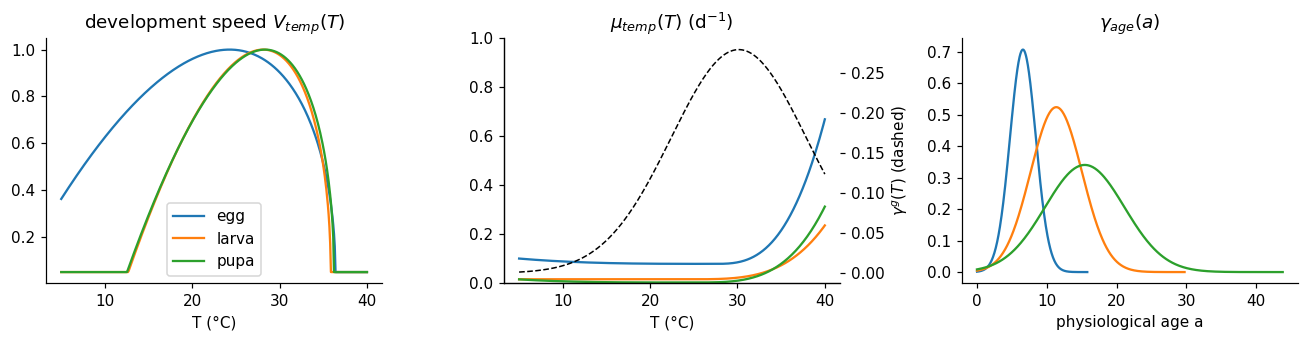

In [6]:
def dev_speed(T, Tmin, Tmax, mindev):
    """V_temp(T), eq. (2.4): Logan-type curve normalised to max 1, floor `mindev`."""
    T = np.asarray(T, float)
    Topt = (Tmin + 2 * Tmax) / 3
    norm = (Topt - Tmin) * np.sqrt(Tmax - Topt)
    inside = (T > Tmin) & (T < Tmax)
    aux = np.where(inside, (T - Tmin) * np.sqrt(np.clip(Tmax - T, 0, None)) / norm, 0.0)
    return (1 - mindev) * aux + mindev

def gamma_age(a, loc, scale, remainder, maxage):
    """γ_age(a), eq. (2.5): Gaussian bump whose integral over [0, a+] is -log(remainder)."""
    norm = stats.norm.cdf(maxage, loc, scale) - stats.norm.cdf(0, loc, scale)
    return -np.log(remainder) / norm * stats.norm.pdf(a, loc, scale)

def mu_temp(T, Mleft, expoleft, Mright, exporight, split, minmu):
    """μ_temp(T), eq. (2.8)."""
    T = np.asarray(T, float)
    return minmu + np.where(T < split, (Mleft * np.abs(T - split)) ** expoleft,
                            (Mright * np.abs(T - split)) ** exporight)

def mu_age(a, Mage, maxage, compat=True):
    return Mage * maxage / (maxage - a) if compat else Mage * a / (maxage - a)

def rain_saturating(R, coeff, half):
    """coeff * (1 - 1/(1 + R/half)): rain-driven wetting (2.6) and adult wash-out (2.9)."""
    return coeff * (1 - 1 / (1 + np.asarray(R) / half))

def gamma_engorged(T, p):
    return np.exp(p["g0"] + p["g1"] * T + p["g2"] * np.asarray(T) ** 2)

# --- figure: the functional forms at the calibrated / laboratory values
Ts = np.linspace(5, 40, 400)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for st, c in zip(LIT.columns, ["C0", "C1", "C2"]):
    q = LIT[st]
    ax[0].plot(Ts, dev_speed(Ts, q.Tmin, q.Tmax, MISC["mindev"]), c, label=st)
    ax[1].plot(Ts, mu_temp(Ts, q.Mleft, q.expoleft, q.Mright, q.exporight, q.split, q.minmu), c)
    amax = q["loc"] + 5 * q["scale"]
    aa = np.linspace(0, amax * 0.999, 400)
    ax[2].plot(aa, gamma_age(aa, q["loc"], q["scale"], q["remainder"], amax), c)
ax[0].set(title="development speed $V_{temp}(T)$", xlabel="T (°C)")
ax[1].set(title=r"$\mu_{temp}(T)$ (d$^{-1}$)", xlabel="T (°C)", ylim=(0, 1))
ax[2].set(title=r"$\gamma_{age}(a)$", xlabel="physiological age a")
ax[0].legend()
ax2 = ax[1].twinx(); ax2.plot(Ts, gamma_engorged(Ts, ADULT), "k--", lw=1)
ax2.set_ylabel(r"$\gamma^g(T)$ (dashed)")
plt.tight_layout(); plt.show()

## 3. Meteorological data, water index and temperature interpolation (article §2.4, §3.1)

The Fortran code reads `data/processed/extended-imputed-meteo.csv` (columns
`station, day, RR, Tmin, Tmax`; already imputed with `mice` and extended backwards for the
spin-up). If it is absent, a **synthetic** Mayotte-like series is generated for 9 stations:
rainy season December–April, dry season June–October, mean temperature 24–28 °C.

In [7]:
STATIONS = pd.DataFrame({   # approximate coordinates — replace with data/raw/meteo-stations-coords.csv
    "name": ["Mtsamboro (Hamjago)", "Dzoumogné", "Mamoudzou", "Vahibé", "Pamandzi (Aéroport)",
             "Coconi-Ouangani", "Dembéni", "Bandrélé", "Kani-Kéli"],
    "lat": [-12.692, -12.716, -12.781, -12.791, -12.805, -12.832, -12.845, -12.908, -12.954],
    "lon": [45.088, 45.104, 45.227, 45.168, 45.281, 45.135, 45.172, 45.193, 45.106]})
coords_file = DATA_DIR / "raw" / "meteo-stations-coords.csv"
if coords_file.exists():
    _c = pd.read_csv(coords_file)            # columns: station, name, lat, lon
    STATIONS = pd.DataFrame({"name": _c.iloc[:, 1], "lat": _c.iloc[:, 2], "lon": _c.iloc[:, 3]})

def synthetic_meteo(n_days, n_stations=9, start_doy=0, seed=1):
    """Synthetic daily (RR, Tmin, Tmax) per station. Day 0 = 1 January."""
    rng = np.random.default_rng(seed)
    doy = (start_doy + np.arange(n_days)) % 365.25
    season = np.cos(2 * np.pi * (doy - 45) / 365.25)          # +1 in mid-February, -1 in August
    common_T = 25.8 + 1.8 * season + np.convolve(rng.normal(0, 0.6, n_days), np.ones(5) / 5, "same")
    p_rain = np.clip(0.35 + 0.30 * season, 0.05, 0.9)
    mean_rain = 4 + 8 * (season + 1)
    out = []
    wet_common = rng.random(n_days)
    for s in range(n_stations):
        wet = (0.7 * wet_common + 0.3 * rng.random(n_days)) < p_rain
        rr = np.where(wet, rng.gamma(0.8, mean_rain / 0.8), 0.0)
        tmean = common_T + rng.normal(0, 0.3, n_days) - 0.3 * (s % 3)
        dtr = 7 + 1.5 * (-season) + rng.normal(0, 0.8, n_days)
        out.append(pd.DataFrame({"station": s, "day": np.arange(n_days), "RR": rr,
                                 "Tmin": tmean - dtr / 2, "Tmax": tmean + dtr / 2}))
    return pd.concat(out, ignore_index=True)

meteo_file = DATA_DIR / "processed" / "extended-imputed-meteo.csv"
if meteo_file.exists():
    METEO = pd.read_csv(meteo_file); METEO.columns = ["station", "day", "RR", "Tmin", "Tmax"]
    METEO["station"] = METEO.groupby("station").ngroup()
    METEO["day"] -= METEO["day"].min()
    SYNTHETIC_METEO = False
else:
    METEO = synthetic_meteo(n_days=6 * 365)     # 2 years spin-up + 4 years of "observations"
    SYNTHETIC_METEO = True
# calendar date of simulation day 0 (day index of the meteo file). For the real data, set it to the
# first date of `extended-imputed-meteo.csv` (including the backward extension used for spin-up).
DATE0 = pd.Timestamp("2016-01-01")
print("synthetic meteo:", SYNTHETIC_METEO, "| days per station:", METEO.day.nunique())

synthetic meteo: True | days per station: 2190


**Water availability index** (eq. (2.2)–(2.3)), port of `calcWater`, and **temperature
interpolation** of Cesaraccio *et al.* (port of `interpTempDay`): sine rise from $T_N$ at sunrise
(06:00) to $T_X$ at 14:00, sine decay to $T_{SS}=T_X-0.39(T_X-T_{N,2})$ at sunset (18:00), then a
square-root decay to the next minimum. Rainfall and $H$ are interpolated linearly with daily values
at noon.

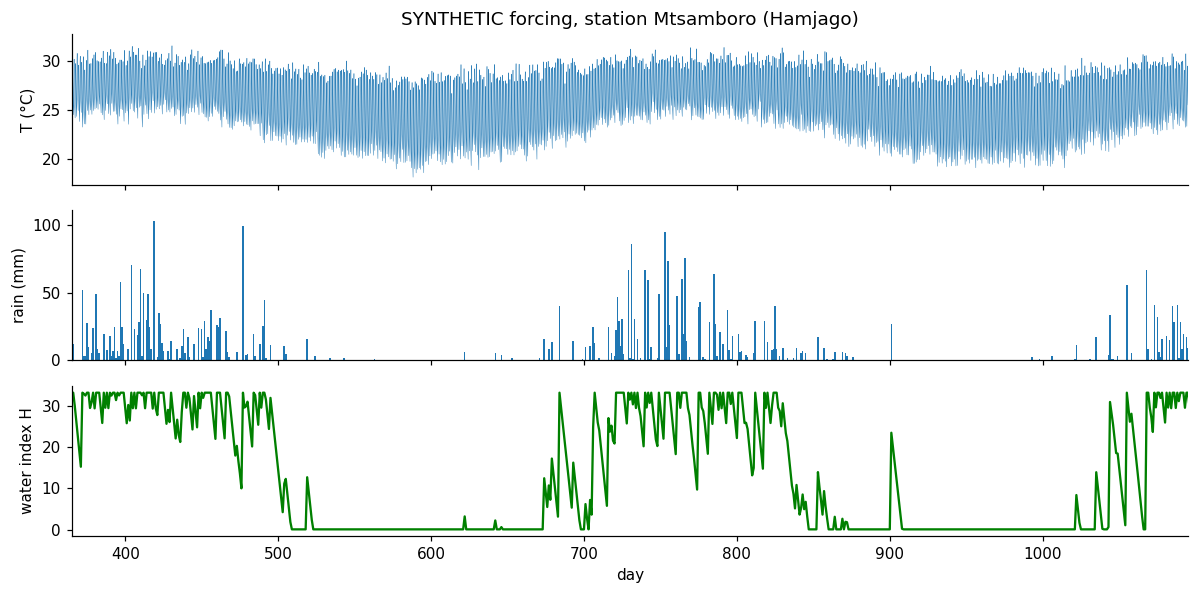

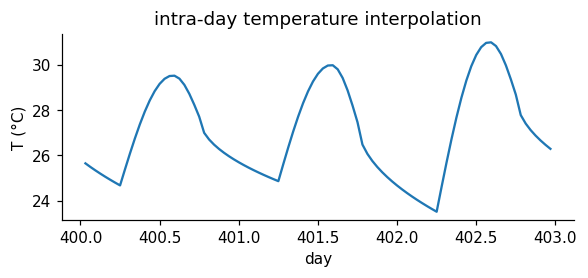

In [8]:
SUNRISE, MAX_HOUR, SUNSET = 6 / 24, 14 / 24, 18 / 24

def water_index(R, Tmean, RH, mincap, maxcap, init=None):
    evap = 6e-5 * (25 + Tmean) ** 2 * (100 - RH)
    H = np.empty(len(R)); H[0] = (mincap + maxcap) / 2 if init is None else init
    for i in range(1, len(R)):
        H[i] = min(max(H[i - 1] + R[i] - evap[i], mincap), maxcap)
    return H

def interp_temperature(t, Tmin, Tmax):
    """Hourly-scale temperature at times t (days, t ≥ SUNRISE) from daily Tmin/Tmax."""
    t = np.asarray(t, float)
    k = np.floor(t - SUNRISE).astype(int)               # day whose sunrise precedes t
    tau = t - k                                          # in [SUNRISE, 1 + SUNRISE)
    k = np.clip(k, 0, len(Tmin) - 2)
    tn1, tx, tn2 = Tmin[k], Tmax[k], Tmin[k + 1]
    tss = tx - 0.39 * (tx - tn2)
    rise = tn1 + (tx - tn1) * np.sin(np.pi / 2 * (tau - SUNRISE) / (MAX_HOUR - SUNRISE))
    fall = tss + (tx - tss) * np.sin(np.pi / 2 * (1 + (tau - MAX_HOUR) / (SUNSET - MAX_HOUR)))
    night = tss + (tn2 - tss) * np.sqrt(np.clip(tau - SUNSET, 0, None) / (1 + SUNRISE - SUNSET))
    return np.where(tau <= MAX_HOUR, rise, np.where(tau <= SUNSET, fall, night))

def interp_noon(t, daily):
    return np.interp(t, np.arange(len(daily)) + 0.5, daily)

def station_forcing(meteo, station, p, dt=DT, t0=None, t1=None):
    """Forcing (T, R, H) on the simulation time grid for one station."""
    m = meteo[meteo.station == station].sort_values("day")
    R, tn, tx = m.RR.values, m.Tmin.values, m.Tmax.values
    H = water_index(R, (tn + tx) / 2, **p["water"])
    t0 = SUNRISE + 1 if t0 is None else t0
    t1 = len(R) - 1.5 if t1 is None else t1
    t = np.arange(t0, t1, dt)
    return dict(t=t, T=interp_temperature(t, tn, tx), R=interp_noon(t, R), H=interp_noon(t, H),
                H_daily=H, R_daily=R)

F0 = station_forcing(METEO, 0, P_ALBO)
fig, ax = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(F0["t"], F0["T"], lw=0.3); ax[0].set_ylabel("T (°C)")
ax[1].bar(np.arange(len(F0["R_daily"])), F0["R_daily"], width=1); ax[1].set_ylabel("rain (mm)")
ax[2].plot(F0["H_daily"], "g"); ax[2].set_ylabel("water index H"); ax[2].set_xlabel("day")
ax[0].set_title(("SYNTHETIC " if SYNTHETIC_METEO else "") + f"forcing, station {STATIONS.name[0]}")
ax[0].set_xlim(365, 3 * 365)
plt.tight_layout(); plt.show()

# zoom on 3 days to show the Cesaraccio shape
sel = (F0["t"] > 400) & (F0["t"] < 403)
plt.figure(figsize=(6, 2.2)); plt.plot(F0["t"][sel], F0["T"][sel]); plt.xlabel("day"); plt.ylabel("T (°C)")
plt.title("intra-day temperature interpolation"); plt.show()

## 4. Simulator (article §2.2 and §3.3)

Port of `simulate`/`calcOneStep`. Aquatic stages use an upwind scheme explicit in age and implicit
in time for the reaction terms; the first age cell of each aquatic stage is a finite volume that
receives the recruitment flux; ODE stages use backward Euler with explicit inflows; the larval
density term uses $L$ at the previous time step. All operations on the age grid are vectorised.

one station, 6.0 years: 1.8 s


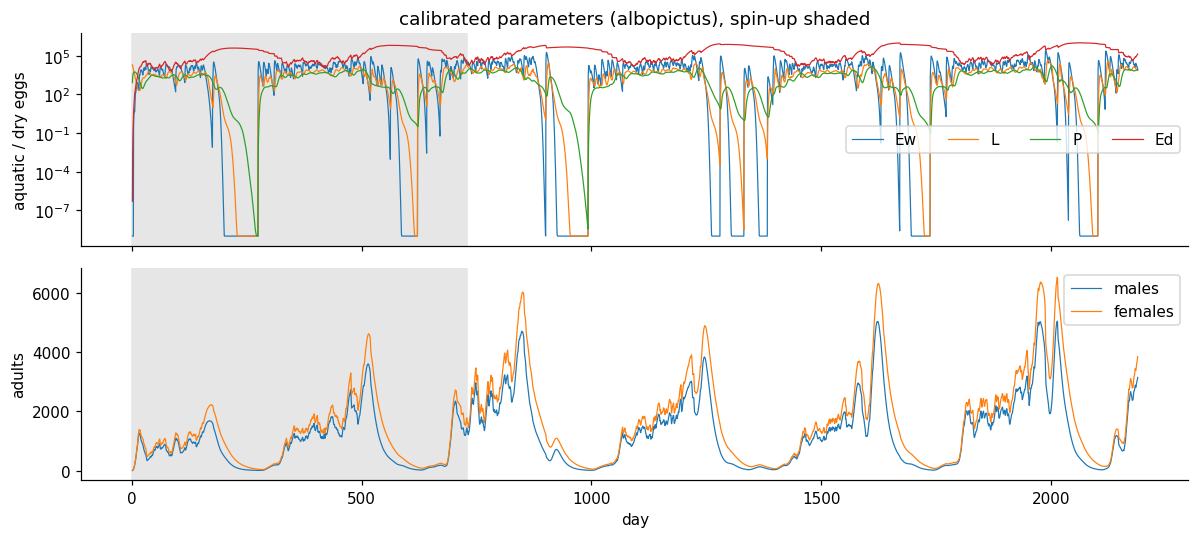

In [9]:
def make_grid(maxages, da=DA):
    sizes = [int(np.floor(m / da)) - 1 for m in maxages]
    idx = np.concatenate([[0], np.cumsum(sizes)])
    ages = np.concatenate([da * np.arange(1, n + 1) for n in sizes])
    stage = np.repeat(np.arange(3), sizes)
    return dict(sizes=sizes, idx=idx, ages=ages, stage=stage, first=idx[:-1], da=da)

def simulate(p, F, dt=DT, da=DA, compat=True, init=None, store_every=None):
    """Run model (2.1)-(2.3). Returns a DataFrame of totals per stage at stored times."""
    g = make_grid(p["maxages"], da)
    st, ages, idx, first = g["stage"], g["ages"], g["idx"], g["first"]
    lit = p["lit"]; cols = list(lit.columns)
    T, R, H = F["T"], F["R"], F["H"]; nt = len(T)
    # time-dependent pre-computations (as in `simulate`)
    dev = np.stack([dev_speed(T, lit[c].Tmin, lit[c].Tmax, p["mindev"]) for c in cols])
    mtemp = np.stack([mu_temp(T, *lit[c][["Mleft", "expoleft", "Mright", "exporight", "split", "minmu"]])
                      for c in cols])
    g_age = np.concatenate([gamma_age(ages[st == s], lit[c]["loc"], lit[c]["scale"], lit[c]["remainder"],
                                      p["maxages"][s]) for s, c in enumerate(cols)])
    m_age = np.concatenate([mu_age(ages[st == s], lit[c].Mage, p["maxages"][s], compat)
                            for s, c in enumerate(cols)])
    cap = p["K"] * H
    death_dry = p["drycor"] * mtemp[0] + p["Mext_phys"][0]
    rain_mort = rain_saturating(R, p["coeff_death_rain"], p["capR_death"])
    mu_m = p["death_male_base"] + rain_mort + p["Mext_adult"]
    mu_f = p["death_female_base"] + rain_mort + p["Mext_adult"]
    tr_dry = rain_saturating(R, p["coeffdry"], p["capR_trans"]) + p["transdrymin"]
    tr_g = gamma_engorged(T, p)
    sigma, beta = p["ratiofem"], p["eggs_per_female_day"]
    te, th, to = p["trans_e"], p["trans_h"], p["trans_o"]
    Lsl, Wsl, Psl = slice(idx[1], idx[2]), slice(idx[0], idx[1]), slice(idx[2], idx[3])
    is_L = (st == 1).astype(float)
    extra_L = 1.0 if compat else 0.0          # calcDeathDensLarvae returns 1 + L/cap in Fortran

    u = np.zeros(len(ages))
    if init is None:                           # Fortran: larvae uniform with total K * Hmax
        u[Lsl] = p["K"] * p["water"]["maxcap"] / p["maxages"][1]
    else:
        u[:] = init
    Ed = Am = Ae = Ah = Ag = Ao = 0.0
    store_every = store_every or max(1, int(round(1 / dt / 4)))   # 4 outputs per day by default
    rec = []
    shifted = np.empty_like(u)
    for i in range(1, nt):
        V = dev[:, i][st]
        trp = dev[:, i - 1][st] * g_age
        trc = dev[:, i][st] * g_age
        Lprev = u[Lsl].sum() * da
        death = mtemp[:, i][st] * (1 + m_age + is_L * (extra_L + Lprev / cap[i])) + p["Mext_phys"][st]
        shifted[1:] = u[:-1]; shifted[first] = 0.0
        x = -(V / da) * (u - shifted)
        x[first[0]] += tr_dry[i - 1] * Ed / da
        x[first[1]] += (u[Wsl] * trp[Wsl]).sum()
        x[first[2]] += (u[Lsl] * trp[Lsl]).sum()
        emerg = (u[Psl] * trp[Psl]).sum() * da
        u_new = (dt * x + u) / (1 + dt * (trc + death))
        # adults and dry eggs (inflows at t_{i-1}, implicit decay at t_i)
        Ed_n = (dt * beta * Ao + Ed) / (1 + dt * (tr_dry[i] + death_dry[i]))
        Am_n = (dt * (1 - sigma) * emerg + Am) / (1 + dt * mu_m[i])
        Ae_n = (dt * sigma * emerg + Ae) / (1 + dt * (te + mu_f[i]))
        Ah_n = (dt * (te * Ae + to * Ao) + Ah) / (1 + dt * (th + mu_f[i]))
        Ag_n = (dt * th * Ah + Ag) / (1 + dt * (tr_g[i] + mu_f[i]))
        Ao_n = (dt * tr_g[i - 1] * Ag + Ao) / (1 + dt * (to + mu_f[i]))
        u, Ed, Am, Ae, Ah, Ag, Ao = u_new, Ed_n, Am_n, Ae_n, Ah_n, Ag_n, Ao_n
        if not np.all(np.isfinite(u)) or u.min() < 0:
            raise FloatingPointError(f"invalid values at step {i}")
        if i % store_every == 0:
            rec.append((F["t"][i], u[Wsl].sum() * da, u[Lsl].sum() * da, u[Psl].sum() * da,
                        Ed, Am, Ae, Ah, Ag, Ao))
    out = pd.DataFrame(rec, columns=["t", "Ew", "L", "P", "Ed", "Am", "Ae", "Ah", "Ag", "Ao"])
    out["female"] = out[["Ah", "Ag", "Ao"]].sum(axis=1)          # Fortran "M-F" output (no Ae)
    out["female_all"] = out[["Ae", "Ah", "Ag", "Ao"]].sum(axis=1)  # article A_f (and QoIs)
    return out

t0 = time.time()
SIM = simulate(P_ALBO, F0)
print(f"one station, {len(F0['t']) * DT / 365:.1f} years: {time.time() - t0:.1f} s")

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for c in ["Ew", "L", "P", "Ed"]:
    ax[0].semilogy(SIM.t, SIM[c] + 1e-9, label=c, lw=0.8)
ax[0].legend(ncol=4); ax[0].set_ylabel("aquatic / dry eggs")
ax[1].plot(SIM.t, SIM.Am, label="males", lw=0.8); ax[1].plot(SIM.t, SIM.female_all, label="females", lw=0.8)
ax[1].legend(); ax[1].set_ylabel("adults"); ax[1].set_xlabel("day")
ax[0].axvspan(0, 730, color="0.9"); ax[1].axvspan(0, 730, color="0.9")
ax[0].set_title("calibrated parameters (albopictus), spin-up shaded")
plt.tight_layout(); plt.show()

**Numerical checks.** (i) *Grid convergence.* The upwind scheme is first order and, with
Δa = 4Δt, runs at CFL number ≤ 0.25, so numerical diffusion is significant on coarse grids.
On the synthetic forcing we measured a maximal relative error of the female curve (against a
reference with Δt = 1/384 d) of ≈ 8 % at the article grid Δt = 1/96 d, ≈ 2.5 % at 1/192 d, and
much more on coarse grids — hence the demos are qualitative. (ii) Positivity is preserved (the
simulator raises an error otherwise). (iii) *Spin-up.* The memory of the initial condition is carried
by the long-lived dry-egg reservoir (minimal mortality 1/400 d⁻¹), so it fades slowly; the cell
below measures it.

In [10]:
F_chk = station_forcing(METEO, 0, P_ALBO, t1=3 * 365)
ref = simulate(P_ALBO, F_chk)
half = simulate(P_ALBO, station_forcing(METEO, 0, P_ALBO, dt=DT / 2, t1=3 * 365), dt=DT / 2, da=DA / 2)
m = ref.t > 730
err = np.abs(ref.female_all[m] - np.interp(ref.t[m], half.t, half.female_all)).max() / half.female_all[m].max()
print(f"grid halved (Δt = {DT:.4f} → {DT / 2:.4f}): max relative change of A_f in year 3 = {err:.2f}")

full = simulate(P_ALBO, F0)
other = simulate(P_ALBO, F0, init=np.full(len(make_grid(P_ALBO["maxages"])["ages"]), 50.0))
rows = []
for d0 in [365, 730, 1095, 1460]:
    m = full.t > d0
    rows.append((d0, np.abs(full.female_all[m] - other.female_all[m]).max() / full.female_all[m].max()))
print(pd.DataFrame(rows, columns=["after day", "max relative difference (two initial data)"]).round(3).to_string(index=False))

grid halved (Δt = 0.0312 → 0.0156): max relative change of A_f in year 3 = 0.15
 after day  max relative difference (two initial data)
       365                                       0.382
       730                                       0.308
      1095                                       0.100
      1460                                       0.062


## 5. Fitting the immature-stage rates to laboratory data (article §4.1)

Port of `calc_dist` and `calcPerformance` from `lit-pcalib.f90`. At constant temperature the
survival to transition $\nu(\theta,T)$ and the mean time to transition $\bar\gamma(\theta,T)$ follow
from eq. (4.1). The Delatte *et al.* tables are read from `data/processed/delatte-{egg,larva,pupa}.csv`
(columns `obs_count, temp, survival(%), mean_duration`). If absent, **pseudo-data** are generated
from the parameters of table 2 with binomial/Gaussian noise, and the fit checks that the method
recovers them.

In [11]:
TEMPS_LAB = np.array([5, 10, 15, 20, 25, 30, 35, 40.0])
P_TEMP = np.array([0, 0, 2, 18, 41, 32, 7, 0]) / 100       # weights of figure 3.1 (thesis)
_hist = DATA_DIR / "processed" / "meteo-hist.csv"
if _hist.exists():
    P_TEMP = pd.read_csv(_hist).iloc[0].values.astype(float)

def lab_survival_and_duration(theta, temps, mindev=0.005, da=2e-3):
    """theta: dict with PARAM_NAMES. Returns (nu, mean duration) at each temperature."""
    maxage = theta["loc"] + 5 * theta["scale"]
    a = np.arange(0, maxage, da)
    norm = stats.norm.cdf(maxage, theta["loc"], theta["scale"]) - stats.norm.cdf(0, theta["loc"], theta["scale"])
    lam = -np.log(theta["remainder"]) / norm
    Ib = -lam * (stats.norm.cdf(a, theta["loc"], theta["scale"]) - stats.norm.cdf(0, theta["loc"], theta["scale"]))
    gam = lam * stats.norm.pdf(a, theta["loc"], theta["scale"])
    with np.errstate(divide="ignore"):
        ageing = theta["Mage"] * (maxage * (np.log(maxage - a) - np.log(maxage)) + a)
    nus, means = [], []
    for T in temps:
        dev = dev_speed(T, theta["Tmin"], theta["Tmax"], mindev)
        t = a / dev
        mt = mu_temp(T, theta["Mleft"], theta["expoleft"], theta["Mright"], theta["exporight"],
                     theta["split"], theta["minmu"])
        Imu = (-t + ageing / dev) * mt
        dist = dev * gam * np.exp(Ib + Imu)
        tot = dist.sum() * da / dev
        nus.append(tot)
        means.append((t * dist).sum() * da / dev / tot if tot > 0 else np.nan)
    return np.array(nus), np.array(means)

def load_or_fake_lab(stage, n_obs=100, seed=3):
    f = DATA_DIR / "processed" / f"delatte-{stage}.csv"
    if stage == "egg":
        f = DATA_DIR / "raw" / "delatte-egg.csv"
    if f.exists():
        d = pd.read_csv(f); d.columns = ["n", "temp", "survival", "mean"]
        d["survival"] /= 100
        return d, False
    rng = np.random.default_rng(seed)
    nu, mean = lab_survival_and_duration(LIT[stage].to_dict(), TEMPS_LAB)
    nu = np.nan_to_num(nu)
    surv = rng.binomial(n_obs, np.clip(nu, 0, 1)) / n_obs
    mean = np.where(surv > 0, mean * (1 + rng.normal(0, 0.05, len(mean))), 0.0)
    return pd.DataFrame({"n": n_obs, "temp": TEMPS_LAB, "survival": surv, "mean": np.nan_to_num(mean)}), True

def lab_bounds(stage, mean25):
    lb = dict(Tmin={"egg": 0, "larva": 10, "pupa": 0}[stage], Tmax=35, remainder=0, loc=0.5 * mean25,
              scale=mean25 / 20, Mage=0.1, Mleft=0, expoleft=1, Mright=0, exporight=1, split=20, minmu=0)
    ub = dict(Tmin={"egg": 5, "larva": 15, "pupa": 15}[stage], Tmax=40, remainder=0.05, loc=2 * mean25,
              scale=mean25, Mage=2, Mleft=0.2, expoleft=4, Mright=0.2, exporight=4, split=30, minmu=2)
    return np.array([lb[k] for k in PARAM_NAMES]), np.array([ub[k] for k in PARAM_NAMES])

def lab_objective_factory(d, weights="code"):
    w_mean = np.sqrt(d.n.values) * P_TEMP
    if weights == "code":        # lit-pcalib.f90: survival weights also multiplied by sqrt(nu)
        w_surv = w_mean * np.sqrt(d.survival.values)
    else:                        # article: w^nu = P sqrt(n), w^gamma = P sqrt(nu n)
        w_surv, w_mean = w_mean, w_mean * np.sqrt(d.survival.values)
    w_mean, w_surv = w_mean / w_mean.sum(), w_surv / w_surv.sum()
    zero = d.survival.values == 0
    def objective(x):
        nu, mean = lab_survival_and_duration(dict(zip(PARAM_NAMES, x)), d.temp.values)
        e_mean = (d["mean"].values - mean) ** 2 / np.sum(w_mean * d["mean"].values ** 2)
        e_mean[zero] = 0
        e_surv = (d.survival.values - nu) ** 2 / np.sum(w_surv * d.survival.values ** 2)
        val = np.dot(e_surv, w_surv) + np.dot(np.nan_to_num(e_mean, nan=1e3), w_mean)
        return val if np.isfinite(val) else 1e8
    return objective

### Cross-entropy optimiser (article appendix B; `mod_cross_entropy.f90`)
Independent truncated-Gaussian sampling, elite set of fixed size, smoothed update of location and
scale. Two stopping rules from the code: the coefficient of variation of the last best values
(`lit-pcalib`), or early stopping on a validation objective (`ce_optimize`).

In [12]:
def truncnorm_draw(rng, loc, scale, lb, ub, n):
    scale = np.maximum(scale, 1e-12)
    a, b = (lb - loc) / scale, (ub - loc) / scale
    return stats.truncnorm.rvs(a, b, loc=loc, scale=scale, size=(n, len(loc)), random_state=rng)

def cross_entropy(objective, lb, ub, init_loc=None, init_scale=None, init_sample=None,
                  n_draw=20, n_elite=3, max_iter=200, loc_smooth=0.5, scale_smooth=0.5,
                  maximize=False, stop="dispersion", verif=10, tol=1e-3, validation=None,
                  fixed=None, rng=RNG, verbose=False):
    lb, ub = np.asarray(lb, float), np.asarray(ub, float)
    if init_sample is not None:
        draw = init_sample
        loc, scale = draw.mean(0), draw.std(0)
    else:
        loc, scale = np.asarray(init_loc, float), np.asarray(init_scale, float)
        draw = truncnorm_draw(rng, loc, scale, lb, ub, n_draw)
    sign = -1 if maximize else 1
    best_hist, best_val, best_x, val_hist = [], np.inf, None, []
    for it in range(1, max_iter + 1):
        if fixed:
            for j, v in fixed.items():
                draw[:, j] = v
        perf = np.array([objective(x) for x in draw]) * sign
        order = np.argsort(perf)
        elites = draw[order[:n_elite]]
        best_hist.append(perf[order[0]])
        if perf[order[0]] < best_val:
            best_val, best_x = perf[order[0]], draw[order[0]].copy()
        loc = loc_smooth * elites.mean(0) + (1 - loc_smooth) * loc
        scale = scale_smooth * elites.std(0) + (1 - scale_smooth) * scale
        if verbose and it % 10 == 0:
            print(f"iter {it:4d}  best {sign * best_hist[-1]:.6g}")
        if stop == "dispersion" and it >= verif:
            h = np.array(best_hist[-verif:])
            if np.std(h, ddof=1) / max(abs(h.mean()), 1e-16) < tol:
                break
        if stop == "validation":
            v = sign * validation(loc)
            val_hist.append(v)
            if v <= min(val_hist):
                best_x_val = loc.copy()
            if it % verif == 0 and min(val_hist[-verif:]) > min(val_hist):
                break
        draw = truncnorm_draw(rng, loc, scale, lb, ub, n_draw)
    if stop == "validation":
        return best_x_val, np.array(best_hist) * sign, it
    return best_x, np.array(best_hist) * sign, it

In [13]:
LAB_FITS, LAB_DATA = {}, {}
for stage in ["egg", "larva", "pupa"]:
    d, fake = load_or_fake_lab(stage)
    LAB_DATA[stage] = d
    mean25 = d.loc[d.temp == 25, "mean"].iloc[0]
    lb, ub = lab_bounds(stage, mean25)
    obj = lab_objective_factory(d)
    t0 = time.time()
    x, hist, it = cross_entropy(obj, lb, ub, (lb + ub) / 2, (ub - lb) / 2, n_draw=20, n_elite=3,
                                max_iter=60 if FAST else 200, rng=np.random.default_rng(7))
    LAB_FITS[stage] = dict(zip(PARAM_NAMES, x))
    print(f"{stage:5s} ({'pseudo-data' if fake else 'Delatte data'}): objective {hist.min():.4f} "
          f"after {it} iterations, {time.time() - t0:.0f} s")

comp = pd.DataFrame({f"{s} (table)": LIT[s] for s in LIT.columns})
for s in LAB_FITS:
    comp[f"{s} (refit)"] = pd.Series(LAB_FITS[s])
comp.round(3)

egg   (pseudo-data): objective 0.0115 after 49 iterations, 1 s
larva (pseudo-data): objective 0.0938 after 49 iterations, 2 s
pupa  (pseudo-data): objective 0.2049 after 43 iterations, 2 s


,egg (table),larva (table),pupa (table),egg (refit),larva (refit),pupa (refit)
Tmin,0.054,12.671,12.534,0.846,11.764,5.156
Tmax,36.388,35.848,36.228,37.054,38.175,37.983
remainder,0.038,0.008,0.008,0.014,0.021,0.021
loc,6.579,11.357,15.433,7.860,11.012,15.261
scale,1.847,3.682,5.681,2.527,4.850,5.882
Mage,1.575,1.934,1.365,1.035,1.208,1.267
Mleft,0.013,0.004,0.014,0.067,0.053,0.093
expoleft,3.101,3.961,3.399,2.830,3.006,3.071
Mright,0.066,0.041,0.047,0.043,0.047,0.028
exporight,2.906,3.618,3.533,3.112,3.201,2.878


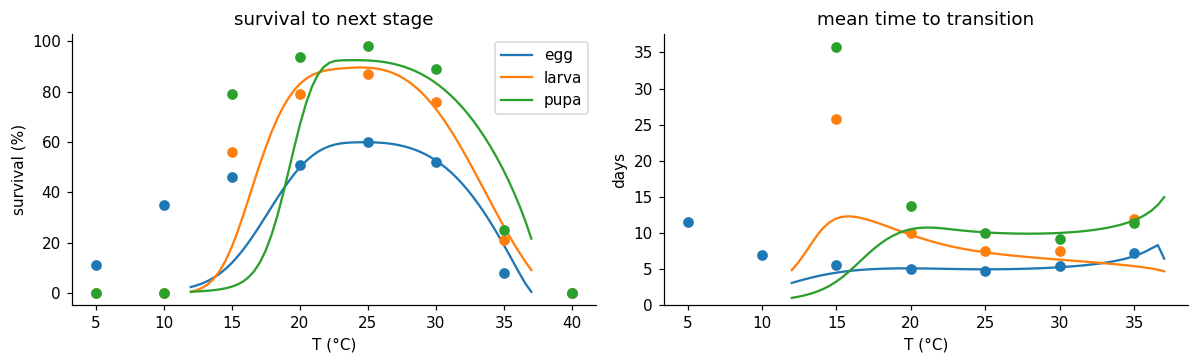

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
Tc = np.linspace(12, 37, 60)
for s, col in zip(LAB_FITS, ["C0", "C1", "C2"]):
    nu, mean = lab_survival_and_duration(LAB_FITS[s], Tc)
    d = LAB_DATA[s]
    ax[0].plot(Tc, 100 * nu, col, label=s); ax[0].plot(d.temp, 100 * d.survival, "o", c=col)
    ax[1].plot(Tc, mean, col); ax[1].plot(d.temp[d.survival > 0], d["mean"][d.survival > 0], "o", c=col)
ax[0].set(xlabel="T (°C)", ylabel="survival (%)", title="survival to next stage")
ax[1].set(xlabel="T (°C)", ylabel="days", title="mean time to transition", ylim=(0, None))
ax[0].legend(); plt.tight_layout(); plt.show()

**Weibull remark (§4.1).** For a Weibull law of shape $k>1$ and mean $W$, $\Pi(W)=\exp[-\Gamma(1+1/k)^k]$
is independent of the scale and lies in $[e^{-1}, e^{-\gamma_{EM}})$, so the mean adult lifespan can
be read where the published survival curves cross ≈ 0.5.

In [15]:
k = np.array([1, 1.5, 2, 3, 5, 10, 100])
print(pd.DataFrame({"shape k": k, "Π(W)": np.exp(-special.gamma(1 + 1 / k) ** k)}).round(3).to_string(index=False))
print("limits:", round(np.exp(-1), 3), round(np.exp(-np.euler_gamma), 3))

 shape k  Π(W)
     1.0 0.368
     1.5 0.424
     2.0 0.456
     3.0 0.491
     5.0 0.521
    10.0 0.545
   100.0 0.568
limits: 0.368 0.561


## 6. Global sensitivity analysis (article §4.2)

**Lemma 4.1 illustrated**: the smooth surrogate $\tau_k(f)=\int t f^k/\int f^k$ converges to the
argmax, and unlike the argmax it does not jump when two peaks have nearly equal height.

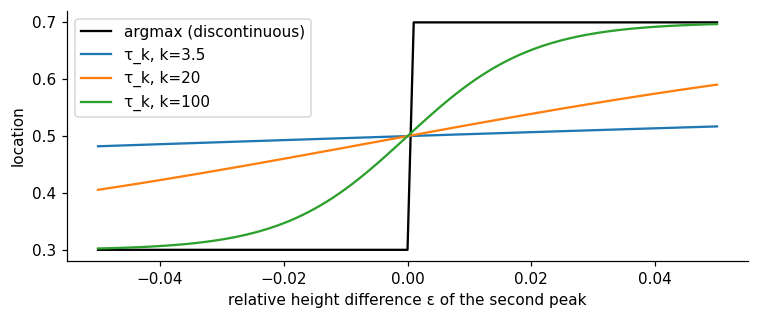

In [16]:
tt = np.linspace(0, 1, 2001)
def two_peaks(eps):
    return np.exp(-((tt - 0.3) / 0.05) ** 2) + (1 + eps) * np.exp(-((tt - 0.7) / 0.05) ** 2)
def soft_argmax(x, t, k):
    w = ((x - x.min()) / (x.max() - x.min())) ** k
    return (t * w).sum() / w.sum()
eps = np.linspace(-0.05, 0.05, 101)
plt.figure(figsize=(7, 3))
plt.plot(eps, [tt[np.argmax(two_peaks(e))] for e in eps], "k", label="argmax (discontinuous)")
for kk in [3.5, 20, 100]:
    plt.plot(eps, [soft_argmax(two_peaks(e), tt, kk) for e in eps], label=f"τ_k, k={kk}")
plt.xlabel("relative height difference ε of the second peak"); plt.ylabel("location"); plt.legend()
plt.tight_layout(); plt.show()

**QoIs** (eq. (4.6)), port of `calcQoIs` in `qoi-simul.f90`: minimum and maximum of the total
female population $A_f=A_e+A_h+A_g+A_o$ over a one-year window after spin-up, and the smooth argmin
and argmax with exponent $k=3.5$ (`EXPO_SOFTARGMAX`). Sobol indices: Saltelli (2010) first-order
and Jansen total-order estimators on Sobol quasi-random matrices — the defaults of the R package
`sensobol` used in the article. The article used $N=2^{11}$ base samples, i.e.
$N(d+2)=40\,960$ simulations; the demo uses a much smaller $N$.

In [17]:
K_SOFT = 3.5

def qois_from_series(x, dt_out):
    t = np.arange(1, len(x) + 1) * dt_out
    return dict(min=x.min(), max=x.max(),
                argmin=soft_argmax(-x, t, K_SOFT), argmax=soft_argmax(x, t, K_SOFT))

# single-station forcing for the sensitivity analysis (water trim 60 d, spin-up, QoI window 360 d)
SPIN_SA = 365 if FAST else 720
_sa_station = 0
_m = METEO[METEO.station == _sa_station]

def run_qoi(field_values):
    p = build_params(field_values)
    F = station_forcing(METEO, _sa_station, p, t0=60.5, t1=60.5 + SPIN_SA + 360)
    out = simulate(p, F, store_every=max(1, int(round(0.25 / DT))))
    w = out[out.t > out.t.max() - 360]
    return qois_from_series(w.female_all.values, 0.25)

def sobol_indices(n_base, names, seed=11, func=run_qoi, verbose=True):
    d = len(names)
    sob = qmc.Sobol(2 * d, scramble=True, seed=seed).random(n_base)
    sob = np.clip(sob, 1e-6, 1 - 1e-6)
    A = np.column_stack([prior_ppf(nm, sob[:, j]) for j, nm in enumerate(names)])
    B = np.column_stack([prior_ppf(nm, sob[:, d + j]) for j, nm in enumerate(names)])
    def evaluate(M):
        return pd.DataFrame([func(dict(zip(names, row))) for row in M])
    t0 = time.time()
    fA, fB = evaluate(A), evaluate(B)
    fAB = []
    for j in range(d):
        ABj = A.copy(); ABj[:, j] = B[:, j]
        fAB.append(evaluate(ABj))
        if verbose:
            pass
    if verbose:
        print(f"{n_base * (d + 2)} simulations done in {time.time() - t0:.0f} s")
    res = []
    for q in fA.columns:
        V = np.var(np.concatenate([fA[q], fB[q]]), ddof=1)
        for j, nm in enumerate(names):
            Si = np.mean(fB[q] * (fAB[j][q] - fA[q])) / V                 # Saltelli 2010
            STi = 0.5 * np.mean((fA[q] - fAB[j][q]) ** 2) / V           # Jansen 1999
            res.append(dict(qoi=q, parameter=nm, first=Si, total=STi))
    return pd.DataFrame(res)

N_SOBOL = 8 if FAST else 2 ** 11
SOBOL = sobol_indices(N_SOBOL, FIELD_NAMES)

160 simulations done in 93 s


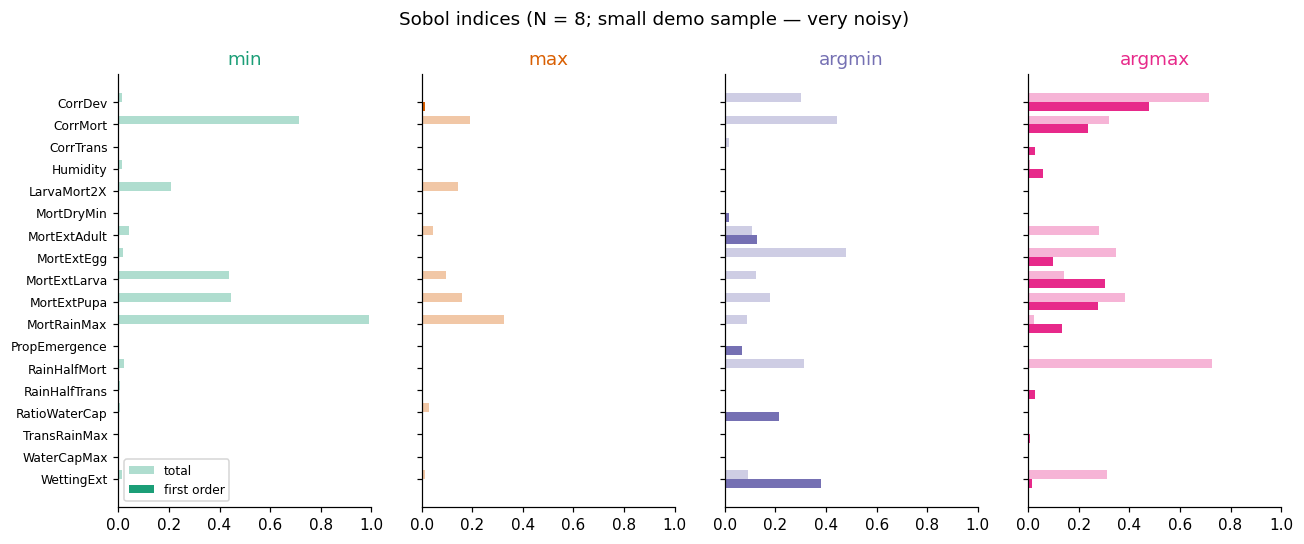

In [19]:
sobol_file = RESULTS_DIR / "misc" / "sobol-indices.csv"

fig, axs = plt.subplots(1, 4, figsize=(12, 5), sharey=True)

for ax, q, c in zip(
    axs,
    ["min", "max", "argmin", "argmax"],
    ["#1B9E77", "#D95F02", "#7570B3", "#E7298A"]
):
    s = (
        SOBOL[SOBOL["qoi"] == q]
        .set_index("parameter")
        .loc[sorted(FIELD_NAMES, reverse=True)]
    )

    y = np.arange(len(s))

    # Indices de sensibilité totaux
    ax.barh(
        y + 0.2,
        s["total"].clip(0, 1),
        height=0.4,
        color=c,
        alpha=0.35,
        label="total"
    )

    # Indices de sensibilité de premier ordre
    ax.barh(
        y - 0.2,
        s["first"].clip(0, 1),
        height=0.4,
        color=c,
        label="first order"
    )

    ax.set_title(q, color=c)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index, fontsize=8)
    ax.set_xlim(0, 1)

axs[0].legend(fontsize=8)

fig.suptitle(
    f"Sobol indices (N = {N_SOBOL}; "
    f"{'small demo sample — very noisy' if N_SOBOL < 256 else 'article setting'})"
)

plt.tight_layout()
plt.show()

With $N=2^{11}$ the article finds that `LarvaMort2X` dominates the magnitude QoIs but not the timing
QoIs, and that Humidity, WaterCapMax, TransRainMax, RainHalfTrans, MortDryMin and PropEmergence
have total indices below ≈ 0.04; these six parameters are fixed (`FIXED`). With the tiny demo
sample the estimates are not reliable: increase `N_SOBOL` (or run `qoi-simul.f90`) to reproduce
figure 3 of the article.

## 7. Spatial interpolation (article §4.3)

Ordinary kriging of $\log S$ with a squared-exponential kernel (`calc_spatial_interp_mat`). The
Fortran code uses the haversine distance in km (`mayotteDist`) and a length scale `width` in km
(search bounds 0.5–40 km).

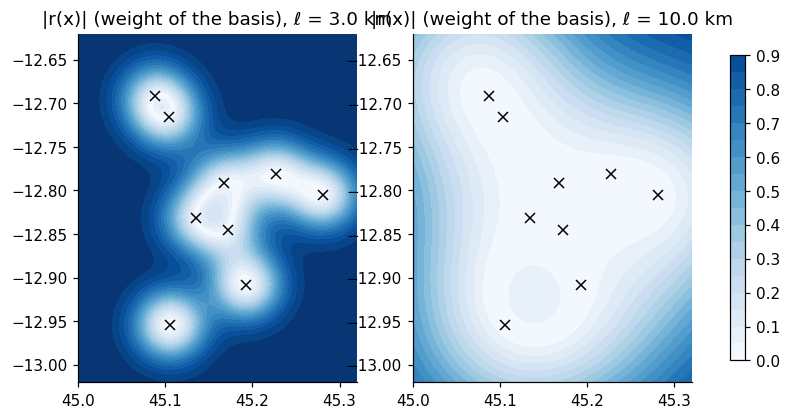

basis coefficients b (sum = 1): [ 0.868 -0.778 -0.086  0.53   0.345  0.525 -0.987  0.388  0.195]


In [20]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = (1 - np.cos(lon2 - lon1)) * np.cos(lat1) * np.cos(lat2) + 1 - np.cos(lat2 - lat1)
    return 2 * 6378 * np.arcsin(np.sqrt(h / 2))

def kriging_weights(width_km, st_lat, st_lon, x_lat, x_lon):
    """Return (W, r, b): log S(x) = W @ log S(stations); r = weight of the basis; b = basis coefficients."""
    D0 = haversine_km(st_lat[:, None], st_lon[:, None], st_lat[None, :], st_lon[None, :])
    D1 = haversine_km(np.asarray(x_lat)[:, None], np.asarray(x_lon)[:, None], st_lat[None, :], st_lon[None, :])
    K0 = np.exp(-D0 ** 2 / (2 * width_km ** 2)); K1 = np.exp(-D1 ** 2 / (2 * width_km ** 2))
    K0inv = np.linalg.inv(K0 + 1e-10 * np.eye(len(K0)))
    h = np.ones(len(K0))
    b = K0inv @ h / (h @ K0inv @ h)
    KK = K1 @ K0inv
    r = 1 - KK @ h
    return KK + np.outer(r, b), r, b

st_lat, st_lon = STATIONS.lat.values, STATIONS.lon.values
glat, glon = np.meshgrid(np.linspace(-13.02, -12.62, 120), np.linspace(45.0, 45.32, 100), indexing="ij")
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a_, w in zip(ax, [3.0, 10.0]):
    W, r, b = kriging_weights(w, st_lat, st_lon, glat.ravel(), glon.ravel())
    im = a_.contourf(glon, glat, np.abs(r).reshape(glat.shape), 20, cmap="Blues", vmin=0, vmax=1)
    a_.plot(st_lon, st_lat, "kx"); a_.set_title(f"|r(x)| (weight of the basis), ℓ = {w} km")
    a_.set_aspect("equal")
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()
print("basis coefficients b (sum = 1):", np.round(b, 3))

## 8. Calibration on sparse capture data (article §4.4)

### 8.1 Marginal Poisson likelihood
With $y_i\sim\mathrm{Pois}(G\omega_i)$ and $G\sim\mathcal U(0,G_+)$,
$\int_0^{G_+}\prod_i \mathrm{Pois}(y_i;G\omega_i)\,\mathrm dG/G_+
=G_+^{-1}\prod_i\frac{\omega_i^{y_i}}{y_i!}\,\Omega^{-(Y+1)}\gamma(Y+1,G_+\Omega)$ (eq. (4.10)).
The log of the lower incomplete gamma function is computed stably (series in log space when the
regularised function underflows), then checked against numerical quadrature.

In [22]:
def log_lower_gamma(a, x):
    """log γ(a, x) (unregularised lower incomplete gamma), stable for small x/a."""
    a, x = float(a), float(x)
    P = special.gammainc(a, x)
    if P > 1e-300:
        return np.log(P) + special.gammaln(a)
    n = np.arange(0, 400)
    log_terms = n * np.log(x) - (special.gammaln(a + n + 1) - special.gammaln(a))
    return a * np.log(x) - x - np.log(a) + special.logsumexp(log_terms)

def log_marginal_poisson(y, omega, Gmax):
    """log of ∫_0^Gmax Π Pois(y_i; G ω_i) dG / Gmax, for one efficiency class."""
    y, omega = np.asarray(y, float), np.asarray(omega, float)
    Y, Om = y.sum(), omega.sum()
    return (-np.log(Gmax) + np.sum(y * np.log(omega) - special.gammaln(y + 1))
            - (Y + 1) * np.log(Om) + log_lower_gamma(Y + 1, Gmax * Om))

# check against quadrature
rng = np.random.default_rng(5)
om = rng.uniform(100, 5000, 30); yy = rng.poisson(2e-4 * om)
from scipy.integrate import quad
num = quad(lambda G: np.exp(np.sum(stats.poisson.logpmf(yy, G * om)) + 60), 0, 1e-3, limit=200)[0]
print("closed form:", log_marginal_poisson(yy, om, 1e-3), "| quadrature:", np.log(num / 1e-3) - 60)

closed form: -25.774154343835026 | quadrature: -25.774154343835022


### 8.2 Field data and log-posterior

Captures are read from the files of the Fortran code (`traps-dates-sexed.csv`: configuration,
set-up day, inspection day, location id; `traps-locs-sexed.csv`: id, lon, lat;
`traps-{albo|aedes}-sexed.csv`: id, males, females). Without them, **synthetic captures** are drawn
from the model run with the calibrated parameters, with four trap configurations whose efficiencies
differ and whose use changes over time (CDC early, outdoor BG-Sentinel late), and with many zeros.

Two observation models are implemented:
* `"article"` – one efficiency $G_k\sim\mathcal U(0,10^{-3})$ per configuration, integrated out
  (eq. (4.11));
* `"code"` – as in `field-pcalib-poiss.f90`: one efficiency per sex, $G\sim\mathcal U(0,0.01)$, and
  relative efficiencies of the configurations fixed beforehand (`multipliers`, estimated by
  `sin-pcalib.f90`).

In [23]:
N_ST = 3 if FAST else 9          # stations simulated in the demos
OBS_START = 2 * 365              # observation period starts after the spin-up

def load_traps(species="albo"):
    fd, fl, fc = (DATA_DIR / "processed" / n for n in
                  ("traps-dates-sexed.csv", "traps-locs-sexed.csv", f"traps-{species}-sexed.csv"))
    if fd.exists() and fl.exists() and fc.exists():
        d = pd.read_csv(fd); d.columns = ["config", "setup", "inspection", "loc", "junk"]
        l = pd.read_csv(fl); l.columns = ["loc", "lon", "lat"]
        c = pd.read_csv(fc); c.columns = ["id", "male", "female"]
        d = d.join(c[["male", "female"]]).merge(l, on="loc", how="left")
        return d, False
    return None, True

def synthetic_traps(sim_by_station, n=400, seed=9):
    rng = np.random.default_rng(seed)
    G_true = np.array([2e-4, 1e-4, 6e-4, 3e-4])     # CDC in, CDC out, BGS in, BGS out
    st = rng.integers(0, N_ST, n)
    lat = st_lat[st] + rng.normal(0, 0.01, n); lon = st_lon[st] + rng.normal(0, 0.01, n)
    setup = np.sort(rng.uniform(OBS_START + 10, sim_by_station[0].t.max() - 3, n))
    frac = (setup - setup.min()) / np.ptp(setup)
    probs = np.column_stack([1 - frac, 1 - frac, 0.3 * frac, 2 * frac]); probs /= probs.sum(1, keepdims=True)
    config = np.array([rng.choice(4, p=pp) for pp in probs]) + 1
    insp = setup + rng.choice([1, 1, 1, 2, 3], n)
    W, _, _ = kriging_weights(5.0, st_lat[:N_ST], st_lon[:N_ST], lat, lon)
    om_m, om_f = exposure(sim_by_station, W, setup, insp)
    G = G_true[config - 1]
    return pd.DataFrame({"config": config, "setup": setup, "inspection": insp, "lat": lat, "lon": lon,
                         "male": rng.poisson(G * om_m), "female": rng.poisson(G * om_f)}), G_true

def exposure(sim_by_station, W, setup, insp):
    """ω_i = ∫ S(t, x_i) dt with S interpolated in log space (eq. (4.7))."""
    t = sim_by_station[0].t.values
    logM = np.log(np.column_stack([s.Am.values for s in sim_by_station]) + 1e-12)
    logF = np.log(np.column_stack([s.female.values for s in sim_by_station]) + 1e-12)
    om_m, om_f = np.empty(len(setup)), np.empty(len(setup))
    for i, (a_, b_) in enumerate(zip(setup, insp)):
        m = (t >= a_) & (t <= b_)
        tt_ = t[m]
        om_m[i] = np.trapezoid(np.exp(logM[m] @ W[i]), tt_)
        om_f[i] = np.trapezoid(np.exp(logF[m] @ W[i]), tt_)
    return om_m, om_f

def run_stations(field, n_st=N_ST):
    p = build_params(field)
    return [simulate(p, station_forcing(METEO, s, p), store_every=max(1, int(round(0.25 / DT))))
            for s in range(n_st)]

t0 = time.time()
SIM_TRUE = run_stations(CALIB["albo"])
print(f"{N_ST} stations simulated in {time.time() - t0:.0f} s")
TRAPS, SYNTHETIC_TRAPS = load_traps("albo")
if SYNTHETIC_TRAPS:
    TRAPS, G_TRUE = synthetic_traps(SIM_TRUE)
print("synthetic captures:", SYNTHETIC_TRAPS, "| inspections:", len(TRAPS),
      "| share of zero counts (females):", round((TRAPS.female == 0).mean(), 2))
TRAPS.head()

3 stations simulated in 5 s
synthetic captures: True | inspections: 400 | share of zero counts (females): 0.59


,config,setup,inspection,lat,lon,male,female
0,1,753.105241,756.105241,-12.725444,45.096754,1,0
1,1,756.374319,759.374319,-12.770425,45.217308,2,1
2,1,758.937771,760.937771,-12.790476,45.236344,0,1
3,1,759.342714,761.342714,-12.690354,45.080517,3,1
4,1,764.488118,765.488118,-12.694527,45.085281,1,0


profile computed in 16 s


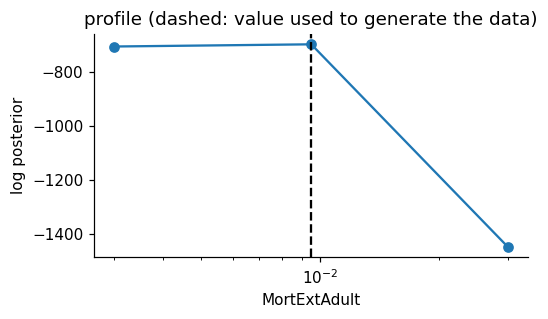

In [24]:
def log_posterior(field, traps=None, model="article", width=5.0, multipliers=None, sims=None):
    traps = TRAPS if traps is None else traps
    sims = run_stations(field) if sims is None else sims
    W, _, _ = kriging_weights(width, st_lat[:N_ST], st_lon[:N_ST], traps.lat.values, traps.lon.values)
    om_m, om_f = exposure(sims, W, traps.setup.values, traps.inspection.values)
    ll = 0.0
    if model == "article":
        for k in np.unique(traps.config):
            m = traps.config.values == k
            ll += log_marginal_poisson(traps.male[m], om_m[m], 1e-3)
            ll += log_marginal_poisson(traps.female[m], om_f[m], 1e-3)
    else:
        mult = np.ones(4) if multipliers is None else multipliers
        c = mult[traps.config.values - 1]
        ll += log_marginal_poisson(traps.male, c * om_m, 0.01)
        ll += log_marginal_poisson(traps.female, c * om_f, 0.01)
    lp = 0.0                                           # log-prior of the free parameters (calcLogPrior)
    for nm, v in field.items():
        if nm in PRIORS and nm not in FIXED and PRIORS[nm] is not None:
            lp += PRIORS[nm].logpdf(v - (50 if nm == "LarvaMort2X" else 0))
    return ll + lp

# profile of the log-posterior along one influential parameter (others at their calibrated values)
grid = np.array([0.003, 0.0095, 0.03])
prof = []
t0 = time.time()
for v in grid:
    prof.append(log_posterior({**CALIB["albo"], "MortExtAdult": v}))
print(f"profile computed in {time.time() - t0:.0f} s")
plt.figure(figsize=(5, 3)); plt.plot(grid, prof, "o-"); plt.axvline(CALIB["albo"]["MortExtAdult"], ls="--", c="k")
plt.xscale("log"); plt.xlabel("MortExtAdult"); plt.ylabel("log posterior")
plt.title("profile (dashed: value used to generate the data)" if SYNTHETIC_TRAPS else "profile")
plt.tight_layout(); plt.show()

### 8.3 What the marginal likelihood identifies
Scaling the simulated abundance by a factor $c$ multiplies every $\omega_i$ by $c$. Once
$G_+\Omega\gg Y$, $\gamma(Y+1,G_+\Omega)\to\Gamma(Y+1)$ and the marginal likelihood no longer depends
on $c$: the captures identify the *shape* of the abundance curve (timing, relative levels between
places and seasons), while the bound $G_+$ only gives a *lower bound* on absolute abundance. This is
consistent with the use of timing QoIs in §6 and with the fact that `LarvaMort2X` (the magnitude
parameter) is the least well constrained. Zero counts are explained by low efficiencies or low
abundance without forcing the whole curve to zero, which is what made least-squares and
correlation losses drift to extinction in the authors' experiments.

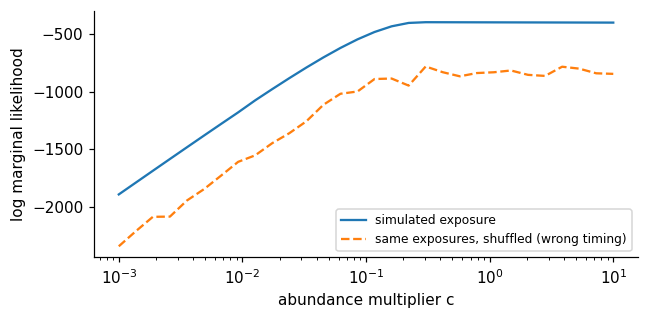

In [25]:
scales = np.logspace(-3, 1, 30)
W_tr = kriging_weights(5.0, st_lat[:N_ST], st_lon[:N_ST], TRAPS.lat, TRAPS.lon)[0]
om_f0 = exposure(SIM_TRUE, W_tr, TRAPS.setup.values, TRAPS.inspection.values)[1]
y = TRAPS.female.values
pois = [log_marginal_poisson(y, s * om_f0, 1e-3) for s in scales]
shuffled = [log_marginal_poisson(y, s * RNG.permutation(om_f0), 1e-3) for s in scales]
plt.figure(figsize=(6, 3))
plt.semilogx(scales, pois, label="simulated exposure")
plt.semilogx(scales, shuffled, "--", label="same exposures, shuffled (wrong timing)")
plt.xlabel("abundance multiplier c"); plt.ylabel("log marginal likelihood"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.4 MAP estimation by cross-entropy (demo)
The article calibrates 13 parameters with 60 draws and 5 elites per iteration, smoothing 0.5 (location)
and 0.1 (scale), early stopping on the last 360 days of data and at most 1000 iterations
(`field-pcalib-poiss.f90`). The demo calibrates two parameters with a few iterations; the
simulations at each draw dominate the cost.

In [26]:
free = ["MortExtAdult", "MortRainMax"]
lb = np.array([0.0, 0.3]); ub = np.array([0.2, 1.5])
start = {**CALIB["albo"]}
def neg_lp(x):
    return log_posterior({**start, **dict(zip(free, x))})
init = np.column_stack([prior_ppf(n, RNG.random(6 if FAST else 60)) for n in free])
t0 = time.time()
x_map, hist, it = cross_entropy(neg_lp, lb, ub, init_sample=init, n_draw=len(init), n_elite=3,
                                max_iter=3 if FAST else 200, loc_smooth=0.5, scale_smooth=0.1,
                                maximize=True, stop="dispersion", verif=3, tol=1e-4)
print(f"{it} iterations in {time.time() - t0:.0f} s; MAP estimate:", dict(zip(free, np.round(x_map, 4))),
      "| value used to generate the data:" if SYNTHETIC_TRAPS else "",
      {k: CALIB['albo'][k] for k in free} if SYNTHETIC_TRAPS else "")

3 iterations in 92 s; MAP estimate: {'MortExtAdult': np.float64(0.0104), 'MortRainMax': np.float64(0.4212)} | value used to generate the data: {'MortExtAdult': 0.0095, 'MortRainMax': 0.385}


## 9. Results (article §5)
If the outputs of `field-pcalib-poiss.f90` are present (`results/simulations/calib-field-*.csv`),
they are plotted as in figures 4–6 of the article; otherwise the demo simulations are used.

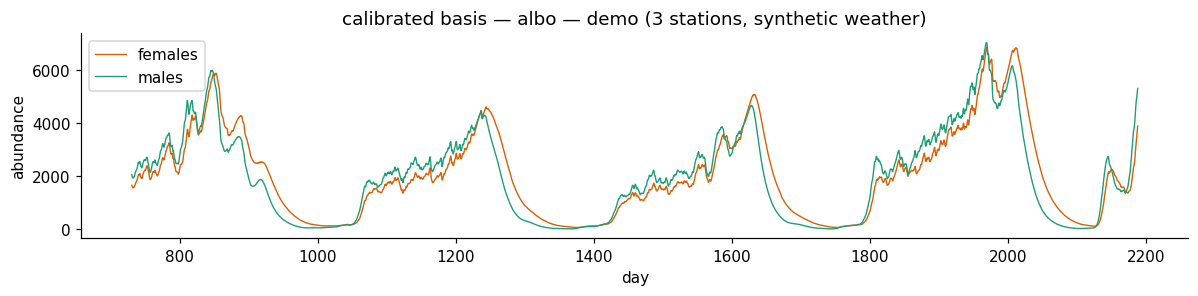

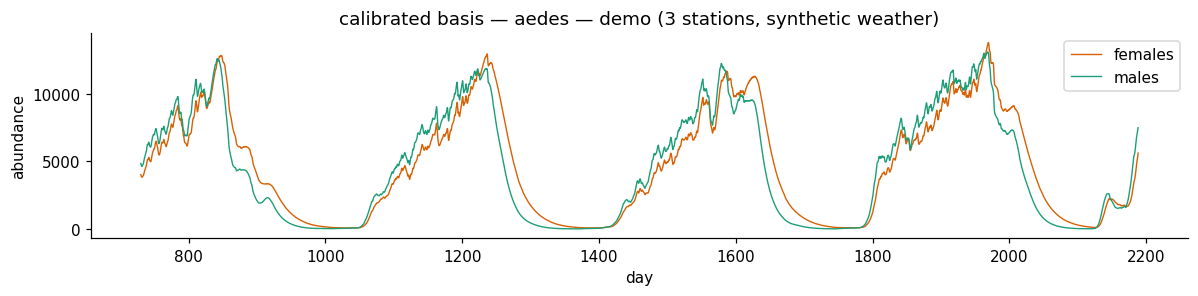

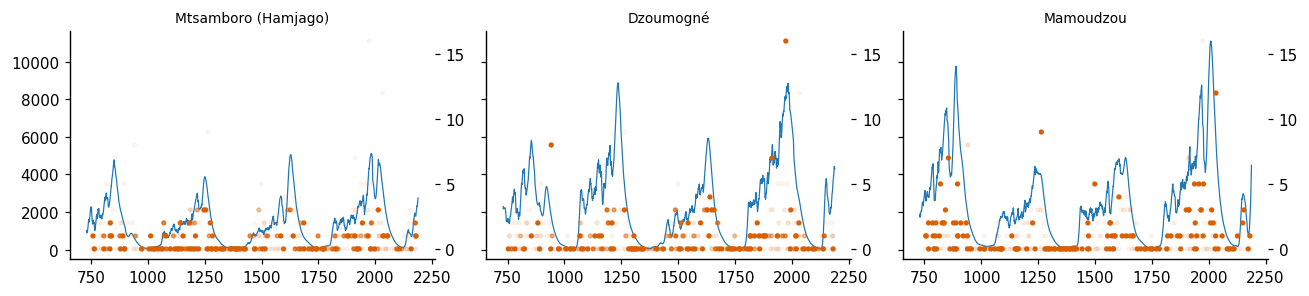

In [27]:
def load_results(species):
    f_f = RESULTS_DIR / "simulations" / f"calib-field-females-{species}.csv"
    f_m = RESULTS_DIR / "simulations" / f"calib-field-males-{species}.csv"
    f_b = RESULTS_DIR / "simulations" / f"calib-field-expbasis-{species}.csv"
    f_i = RESULTS_DIR / "simulations" / f"calib-field-info-{species}.csv"
    if all(f.exists() for f in (f_f, f_m, f_b, f_i)):
        info = pd.read_csv(f_i, header=None, index_col=0).iloc[:, 0]
        fem, mal, basis = pd.read_csv(f_f), pd.read_csv(f_m), pd.read_csv(f_b, header=None)
        t = info["t0_simul"] + np.arange(len(fem)) / info["1/Dt"]
        return dict(t=t, females=fem, males=mal, basis=basis), False
    return None, True

for species in ["albo", "aedes"]:
    res, missing = load_results(species)
    if missing:
        sims = SIM_TRUE if species == "albo" else run_stations(CALIB["aedes"])
        t = sims[0].t.values
        logF = np.log(np.column_stack([s.female.values for s in sims]))
        logM = np.log(np.column_stack([s.Am.values for s in sims]))
        _, _, b = kriging_weights(5.0, st_lat[:N_ST], st_lon[:N_ST], [st_lat[0]], [st_lon[0]])
        basisF, basisM = np.exp(logF @ b), np.exp(logM @ b)
        label = f"demo ({N_ST} stations, {'synthetic' if SYNTHETIC_METEO else 'real'} weather)"
    else:
        t = res["t"].values; basisM, basisF = res["basis"][0].values, res["basis"][1].values
        label = "results of field-pcalib-poiss.f90"
    m = t > OBS_START if missing else slice(None)
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(t[m], basisF[m], c="#D95F02", lw=0.9, label="females")
    ax.plot(t[m], basisM[m], c="#1B9E77", lw=0.9, label="males")
    ax.set(title=f"calibrated basis — {species} — {label}", xlabel="day", ylabel="abundance")
    ax.legend(); plt.tight_layout(); plt.show()

# simulated female abundance and captures by station (figure 5 layout, demo)
fig, axs = plt.subplots(1, N_ST, figsize=(4 * N_ST, 2.8), sharey=True)
W, _, _ = kriging_weights(5.0, st_lat[:N_ST], st_lon[:N_ST], TRAPS.lat, TRAPS.lon)
for s, ax in enumerate(np.atleast_1d(axs)):
    sim = SIM_TRUE[s]; m = sim.t > OBS_START
    ax.plot(sim.t[m], sim.female[m], lw=0.8)
    ax2 = ax.twinx()
    ax2.scatter(TRAPS.setup, TRAPS.female, s=6, c="#D95F02", alpha=np.clip(W[:, s], 0.05, 1))
    ax.set_title(STATIONS.name[s], fontsize=9)
plt.tight_layout(); plt.show()

## 9b. Predictive maps of Mayotte

The model is run at every weather station with the calibrated parameters, then the abundance is
interpolated over the island with the kriging of §7 (eq. (4.7)), in log space. This gives, for any
date, a map of predicted female (or male) abundance; from the space–time field we also derive
seasonal means, the timing of the seasonal peak (smooth argmax of §6) and an animation.

**Land mask.** If `geopandas` and the shapefile used in the R scripts (`data/raw/admin-departement.shp`)
are available, the island outline comes from the shapefile. Otherwise an embedded raster mask is
used, digitised from the Wikimedia map of the communes (UTM/WGS84 graticule, ≈ 230 m resolution).

**Caveats.** (i) Absolute levels are only defined up to the trap efficiency (§8.3): read the maps
as *relative* abundance. (ii) Between stations the prediction relies on the kriging; far from all
stations it reverts to the island-wide basis (the map of $|r(x)|$ in §7 shows where). (iii) With
synthetic weather (default when the Météo-France file is absent) the maps only illustrate the method.

In [28]:
import zlib, base64
from matplotlib.path import Path as MplPath
from matplotlib import animation, colors

MASK_SHAPE = (268, 203)
MASK_LON = (45.01802, 45.29868)
MASK_LAT = (-12.63667, -13.00136)
MASK_B64 = (
    "eNqtWTuOHDcQJdXAtgALpkIHC1OZQqUKBFGhM19hM6cOHQggDV3AN/BVqMihfQABogDlogEHHRBND5vN/rDqYXeAnWAHOzWv"
    "Xn3J6pobgV4RCbQDgnECApkdEiCIQZAhJ4EkyDDjESQsb0+p5HW1j2pU9e2O+uKRrp+Wv0+o4PkRyFiHgiMMEowoaxLq+g0J"
    "bpHgRyQYUAJEQIK34vpiQsrMDCvjPyCxGQhU9kgXb9ggMqg/Y/MMPMnAF52vhpgMGmO8QKCuiHTx9K8QfSHhIRmx6CJxQBfn"
    "yzgUQf7Kc7DKTBX8wXOwvtgM6BUikffomqGuwFQXgmQE0Qiy+kgLeTWYSYvZdQXO4EL/7EzyeYP055jeILcs/wUyepY/CJl4"
    "X74K+9FzcclRd56u9DldsOkToyu7PjpNMBU70h2xq2mkcVlfJJGZ5uAsmJDgUGhn9kOmO/Y9obIT5BdA165s7CEB2LVDvoMQ"
    "9QqZ7JHJz3tnUCgPZQsD00M8qYpD+Ac2ZG7rAU3pbzlIoV8L2liiqxaN/EAC1oYT/WdXYmqtM/mlC8vQ/LnVna6tnIZO1z5O"
    "2bMutSVNn+O1z1lD5/wezk6X2SDqDPl5g8hzWPTeAPYE+WUvgFP4l/8iU/1B7gVwyv6npbIdLZiwcAbWR8XaNVVrqI9z9SxQ"
    "H6sDM+0xX79IIxkrZCIs86qbZsVX1wLp1+k8sOiuuWykx8Wia0yCt0tYevTU724nuTySlLBPtFv9MnRqevREodw2lR/pUx1g"
    "31OIW/QoRyChDsORQFJtxht68K7T/R1xMtTL7YacL825d4QeXNP0Oh4yutotuqcVvYi64DukK1yvyyNdM9JF6CX0UdN78Jyv"
    "WaApxaPpaYKQR5jE5GfkikGRVKgmZEYZhiHOKJI6I/oN8g+y6xFYZEbl8gBIgBKHTI7I5AQbzz04+gYlbDtD/vUgYaT4xoyU"
    "3e9keLCTsMQE1DUgXZv7HkEmBEmojfIjdnECj4zsg7kFiDVi3c4ibWVxMevXI3Fq9BeS709aXKMX9b7bimtq9L5tepqtDTL1"
    "tsaWsN69uVkc+uz6FZJ696YG8X3Vt7KY+kbxDdI3SmppCdyWztIjpI6VI4XI+k3m1Kn0ujywBWbjUuj7bZFt9OGYrIV49T6x"
    "e0XJNN2wfGSYKnpTPhqZY2JcBnHu6nQmH0fFzrIRLAuKromr1FjsYhc4TqHFg2WvTn3PdZfQEoPpU4X6dD1Yv6EGji9AAyeB"
    "dDlkV4Q+CuRjQMuVdMUhpRBEocMTDloDHNrybNB48IG/uJ/aaMDZnVCM3whg8ZM1lOmaUMKd1/V7KgFvqHan/80O07NGE9Xv"
    "6Or0GlydceCG1mXZainJUNYbbmQsjssj5XvDbNlLrSr6I8C49Lb0P1BdstC/piF+Vrx0I3PbOfXXxQ3P/QQR7dTt9JplauZ+"
    "ACl1gZbjQsOtPdrNi5dniv8B6JIv6g=="
)

def embedded_land_mask():
    bits = np.frombuffer(zlib.decompress(base64.b64decode("".join(MASK_B64))), dtype=np.uint8)
    m = np.unpackbits(bits)[: MASK_SHAPE[0] * MASK_SHAPE[1]].reshape(MASK_SHAPE).astype(bool)
    lats = np.linspace(MASK_LAT[0], MASK_LAT[1], MASK_SHAPE[0])
    lons = np.linspace(MASK_LON[0], MASK_LON[1], MASK_SHAPE[1])
    return lons, lats, m

def land_grid(step=1):
    """Return (lon2d, lat2d, mask, outlines) for the island; outlines = list of (lon, lat) arrays or None."""
    shp = DATA_DIR / "raw" / "admin-departement.shp"
    try:
        import geopandas as gpd
        if not shp.exists():
            raise FileNotFoundError
        gdf = gpd.read_file(shp).to_crs(4326)
        lons = np.arange(45.00, 45.31, 0.0022); lats = np.arange(-13.01, -12.62, 0.0022)[::-1]
        LON, LAT = np.meshgrid(lons, lats)
        pts = np.column_stack([LON.ravel(), LAT.ravel()]); inside = np.zeros(len(pts), bool); outlines = []
        for geom in gdf.geometry:
            for poly in getattr(geom, "geoms", [geom]):
                xy = np.asarray(poly.exterior.coords)
                inside |= MplPath(xy).contains_points(pts); outlines.append(xy)
        return LON, LAT, inside.reshape(LON.shape), outlines
    except Exception:
        lons, lats, m = embedded_land_mask()
        LON, LAT = np.meshgrid(lons[::step], lats[::step])
        return LON, LAT, m[::step, ::step], None

LON, LAT, LAND, OUTLINES = land_grid(step=2 if FAST else 1)
print(f"map grid {LON.shape}, {LAND.sum()} land cells",
      "(shapefile outline)" if OUTLINES else "(embedded raster mask)")

map grid (134, 102), 4208 land cells (embedded raster mask)


In [29]:
SPECIES_MAP = "albo"            # "albo" or "aedes" (calibration 1 or 2 of the article)
WIDTH_MAP_KM = 2.8              # kriging length; article: 0.025 deg ≈ 2.8 km (see §10, item 9)

t0 = time.time()
SIM_MAP = run_stations(CALIB[SPECIES_MAP], n_st=len(STATIONS))
print(f"{len(STATIONS)} stations simulated in {time.time() - t0:.0f} s")

W_MAP, R_MAP, _ = kriging_weights(WIDTH_MAP_KM, st_lat, st_lon, LAT[LAND], LON[LAND])
t_map = SIM_MAP[0].t.values
keep = t_map > OBS_START
t_map = t_map[keep]
logF = np.log(np.column_stack([s.female_all.values[keep] for s in SIM_MAP]) + 1e-12)
logM = np.log(np.column_stack([s.Am.values[keep] for s in SIM_MAP]) + 1e-12)

def field_at(times, log_st=logF):
    """Predicted abundance on land cells at given times -> array (len(times), n_land)."""
    idx = np.searchsorted(t_map, np.atleast_1d(times)).clip(0, len(t_map) - 1)
    return np.exp(log_st[idx] @ W_MAP.T)

def to_grid(values):
    g = np.full(LAND.shape, np.nan); g[LAND] = values; return g

def draw_island(ax, values, title, cmap="YlOrRd", norm=None, cbar_label="", traps=True):
    extent = [LON.min(), LON.max(), LAT.min(), LAT.max()]
    im = ax.imshow(to_grid(values), origin="upper" if LAT[0, 0] > LAT[-1, 0] else "lower",
                   extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    if OUTLINES:
        for xy in OUTLINES:
            ax.plot(xy[:, 0], xy[:, 1], "k", lw=0.5)
    else:
        ax.contour(LON, LAT, LAND.astype(float), levels=[0.5], colors="k", linewidths=0.5)
    ax.plot(st_lon, st_lat, "x", c="k", ms=6, mew=1.5)
    if traps and "lon" in TRAPS and not SYNTHETIC_TRAPS:
        ax.plot(TRAPS.lon, TRAPS.lat, "o", ms=2, mfc="white", mec="0.3", mew=0.4, alpha=0.6)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, shrink=0.75, label=cbar_label)
    return im

9 stations simulated in 15 s


### Snapshots through one year
Predicted female abundance on the first day of selected months (log colour scale, common to all
panels), for the last complete year of the simulation.

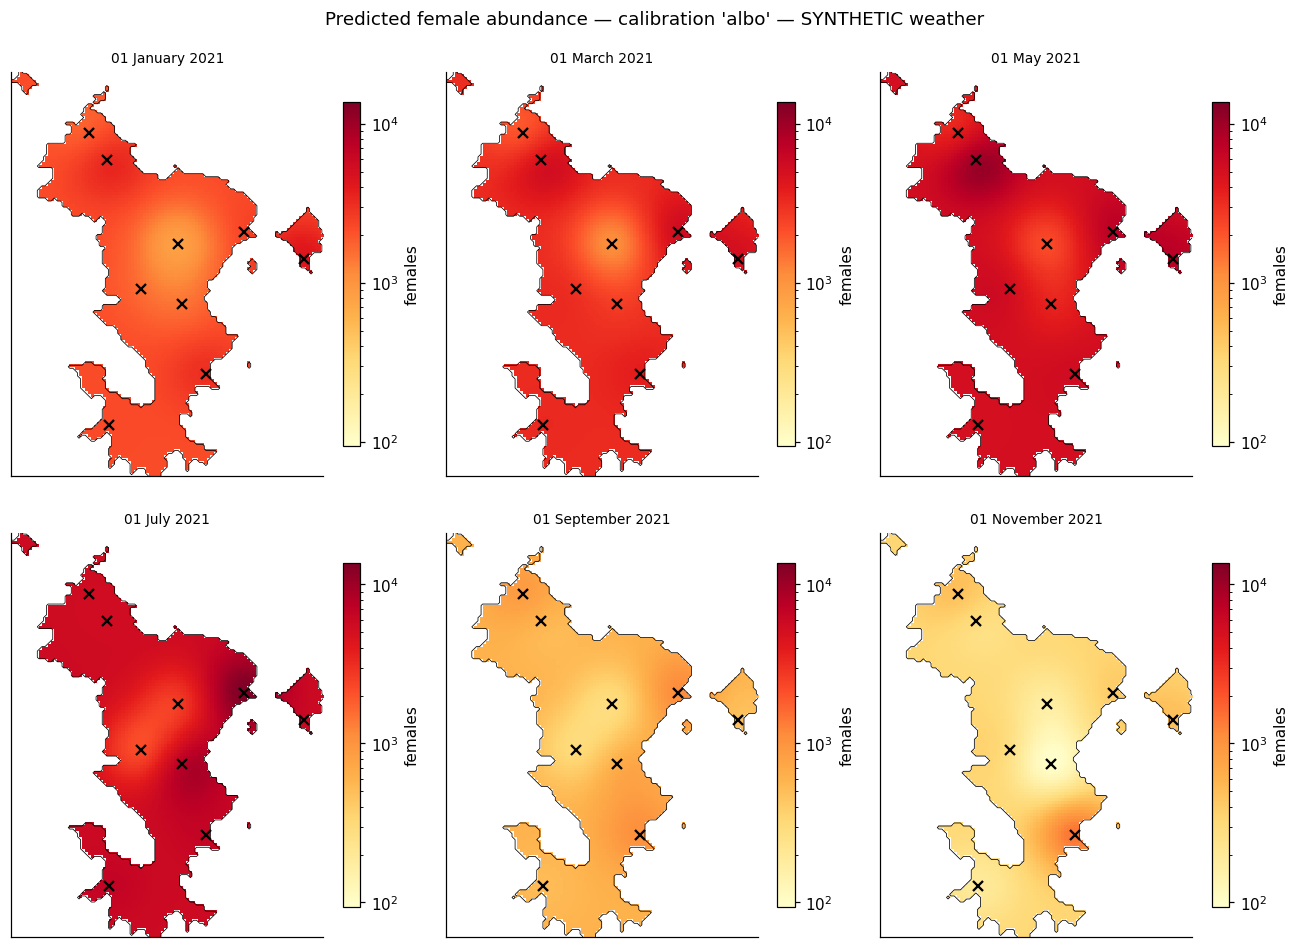

In [30]:
def to_date(t):
    return DATE0 + pd.to_timedelta(t, unit="D")

def day_to_month(t):
    return to_date(t).month - 1

last_year = t_map[t_map > t_map.max() - 365]
month_starts = []
for m in [0, 2, 4, 6, 8, 10]:                       # Jan, Mar, May, Jul, Sep, Nov
    cand = last_year[[day_to_month(t) == m for t in last_year]]
    month_starts.append(cand[0])
F_snap = field_at(month_starts)
norm = colors.LogNorm(vmin=max(F_snap.min(), F_snap.max() * 1e-3), vmax=F_snap.max())
names = ["January", "March", "May", "July", "September", "November"]
fig, axs = plt.subplots(2, 3, figsize=(12, 9))
for ax, v, nm, t in zip(axs.ravel(), F_snap, names, month_starts):
    draw_island(ax, v, f"{to_date(t):%d %B %Y}", norm=norm, cbar_label="females")
fig.suptitle(f"Predicted female abundance — calibration '{SPECIES_MAP}'"
             + (" — SYNTHETIC weather" if SYNTHETIC_METEO else ""))
plt.tight_layout(); plt.show()

### Seasonal means, timing of the peak and spatial contrast
* rainy-season (Dec–Apr) and dry-season (Jun–Oct) mean abundance;
* date of the seasonal peak, computed per cell with the smooth argmax ($k=3.5$) on the last year;
* ratio between rainy- and dry-season means, a proxy for how strongly control should be timed.

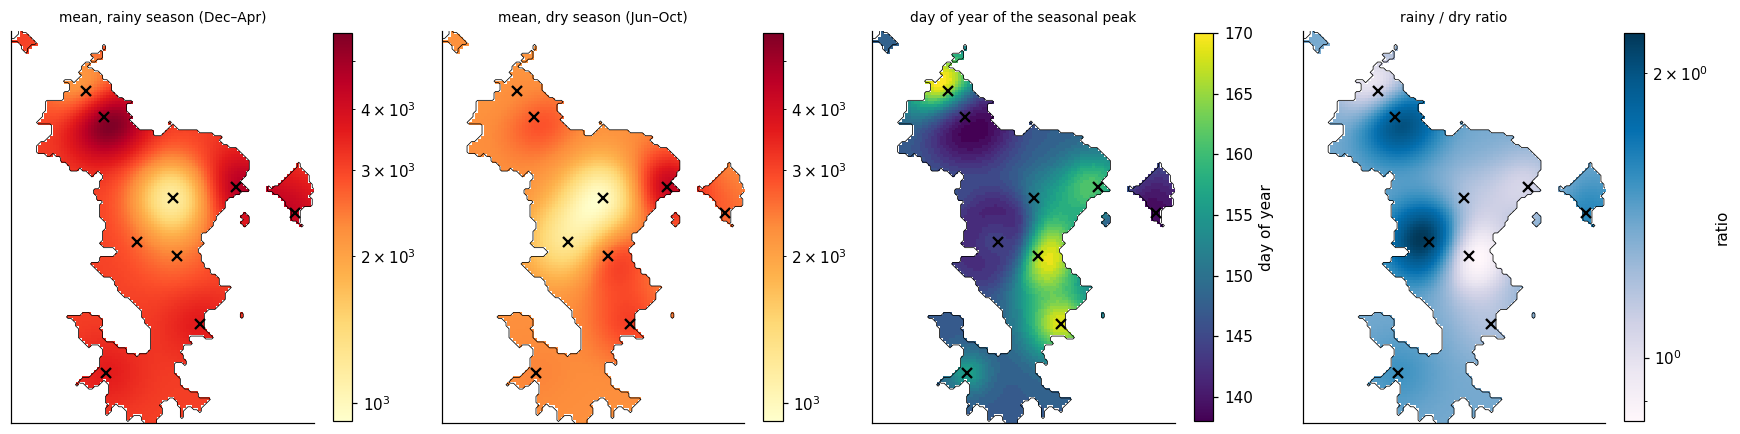

In [31]:
ly = t_map > t_map.max() - 365
t_ly = t_map[ly]
months_ly = np.array([day_to_month(t) for t in t_ly])
step = max(1, int(round(1 / (t_ly[1] - t_ly[0]))))          # daily sub-sampling
sel = np.arange(0, ly.sum(), step)
F_ly = np.exp(logF[ly][sel] @ W_MAP.T)                     # (days, land cells)
mo = months_ly[sel]
rainy = np.isin(mo, [11, 0, 1, 2, 3]); dry = np.isin(mo, [5, 6, 7, 8, 9])
mean_rainy, mean_dry = F_ly[rainy].mean(0), F_ly[dry].mean(0)
tt_ = (t_ly[sel] - t_ly[0])
w = ((F_ly - F_ly.min(0)) / np.ptp(F_ly, axis=0).clip(1e-12)) ** K_SOFT
peak_day = (tt_[:, None] * w).sum(0) / w.sum(0) + t_ly[0]
peak_doy = np.array(pd.DatetimeIndex(to_date(peak_day)).dayofyear, float)

fig, axs = plt.subplots(1, 4, figsize=(16, 5))
vmin, vmax = min(mean_rainy.min(), mean_dry.min()), max(mean_rainy.max(), mean_dry.max())
draw_island(axs[0], mean_rainy, "mean, rainy season (Dec–Apr)", norm=colors.LogNorm(vmin, vmax))
draw_island(axs[1], mean_dry, "mean, dry season (Jun–Oct)", norm=colors.LogNorm(vmin, vmax))
draw_island(axs[2], peak_doy, "day of year of the seasonal peak", cmap="viridis", cbar_label="day of year")
draw_island(axs[3], mean_rainy / mean_dry.clip(1e-9), "rainy / dry ratio", cmap="PuBu",
            norm=colors.LogNorm(), cbar_label="ratio")
plt.tight_layout(); plt.show()

### Island-wide time series and per-commune summary
The basis (kriging mean) and the 10–90 % range over land cells; if the communes shapefile and
`geopandas` are available, the mean predicted abundance is also tabulated by commune.

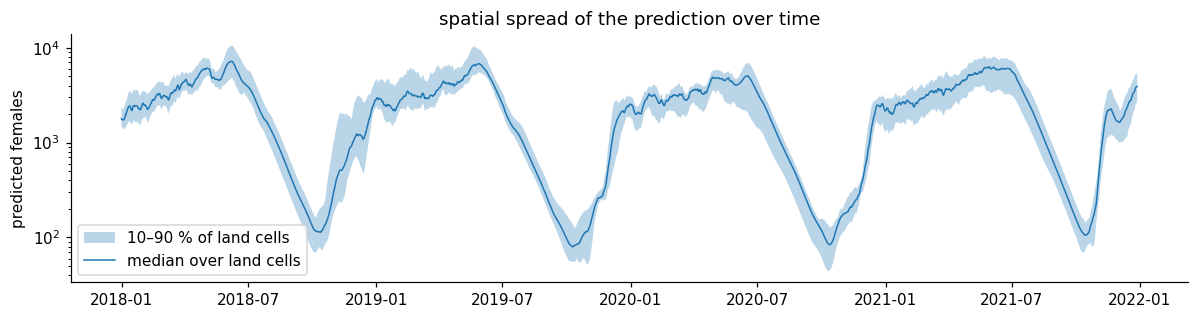

commune table skipped (needs geopandas and data/raw/MayotteCommunesGEOFLA.shp): ModuleNotFoundError


In [33]:
F_all = np.exp(logF[::max(1, int(round(1 / (t_map[1] - t_map[0]))))] @ W_MAP.T)
tt_all = t_map[::max(1, int(round(1 / (t_map[1] - t_map[0]))))]
q10, q50, q90 = np.percentile(F_all, [10, 50, 90], axis=1)
plt.figure(figsize=(11, 3))
plt.fill_between(to_date(tt_all), q10, q90, alpha=0.3, label="10–90 % of land cells")
plt.plot(to_date(tt_all), q50, lw=1, label="median over land cells")
plt.yscale("log"); plt.ylabel("predicted females"); plt.legend()
plt.title("spatial spread of the prediction over time"); plt.tight_layout(); plt.show()

com_shp = DATA_DIR / "raw" / "MayotteCommunesGEOFLA.shp"
try:
    import geopandas as gpd
    com = gpd.read_file(com_shp).to_crs(4326)
    pts = np.column_stack([LON[LAND], LAT[LAND]])
    rows = []
    for _, r in com.iterrows():
        inside = np.zeros(len(pts), bool)
        for poly in getattr(r.geometry, "geoms", [r.geometry]):
            inside |= MplPath(np.asarray(poly.exterior.coords)).contains_points(pts)
        if inside.any():
            rows.append(dict(commune=r.get("nom_com", r.iloc[0]), rainy=mean_rainy[inside].mean(),
                             dry=mean_dry[inside].mean(), peak_doy=np.median(peak_doy[inside])))
    COMMUNES = pd.DataFrame(rows).sort_values("rainy", ascending=False)
    from IPython.display import display
    display(COMMUNES.round(1))
except Exception as e:
    print("commune table skipped (needs geopandas and data/raw/MayotteCommunesGEOFLA.shp):", type(e).__name__)

### Animation
Monthly-resolution animation of the predicted female abundance over the last two simulated years,
saved as a GIF (`results/plots/mayotte-prediction.gif`) that can be inserted in a presentation.

In [30]:
frames_t = t_map[(t_map > t_map.max() - 730)][:: max(1, int(round(7 / (t_map[1] - t_map[0]))))]  # weekly
F_frames = field_at(frames_t)
norm = colors.LogNorm(vmin=max(F_frames.min(), F_frames.max() * 1e-3), vmax=F_frames.max())
fig, ax = plt.subplots(figsize=(4.5, 5.5))
im = draw_island(ax, F_frames[0], "", norm=norm, cbar_label="females")
def update(k):
    im.set_data(to_grid(F_frames[k])); ax.set_title(f"{to_date(frames_t[k]):%d %b %Y}", fontsize=9); return (im,)
ani = animation.FuncAnimation(fig, update, frames=len(frames_t), interval=120, blit=False)
out_gif = RESULTS_DIR / "plots" / "mayotte-prediction.gif"
out_gif.parent.mkdir(parents=True, exist_ok=True)
ani.save(out_gif, writer=animation.PillowWriter(fps=8))
plt.close(fig)
print("animation written to", out_gif, f"({len(frames_t)} frames)")

animation written to results/plots/mayotte-prediction.gif (105 frames)


## 10. Consistency between the Fortran code and the article

Reading the code while porting it revealed the following points. They should be settled before
submission (either fix the code and rerun, or change the text).

| # | topic | Fortran code | article | effect |
|---|---|---|---|---|
| 1 | ageing mortality in the simulator | `calcDeathAge` = $M_{age}\,a_+/(a_+-a)$ | $M_{age}\,a/(a_+-a)$ (also used in the lab fit) | simulator adds a constant $M_{age}\mu_{temp}$ to aquatic mortality |
| 2 | larval density term | `1 + death_age + (1 + L/cap)` | $1+\mu_{age}+L/(KH)$ | baseline larval temperature mortality doubled |
| 3 | $\gamma_{age}$ normalisation | `calcTransAge` multiplies by $\Phi(a_+)-\Phi(0)$ | lab fit divides | negligible (factor ≈ 1) |
| 4 | floor $\underline V$ | 0.005 in `lit-pcalib`, 0.05 in the simulations | single $\underline V$ | lab fit and model use different development curves at low temperature |
| 5 | lab-fit weights | survival: $P\sqrt{n\nu}$, durations: $P\sqrt n$ | survival $P\sqrt n$, durations $P\sqrt{n\nu}$ | text and code swapped |
| 6 | $a_+^{\rm w}$ after correction | computed from uncorrected loc/scale | scaled by $\xi_V$ | grid of wet eggs not rescaled |
| 7 | female total in calibration | `M-F` output = $A_h+A_g+A_o$ | $A_f=A_e+A_h+A_g+A_o$ | QoIs include $A_e$, calibration does not |
| 8 | trap efficiency | one $G$ per sex, $G\sim\mathcal U(0,0.01)$, configuration multipliers fixed beforehand by `sin-pcalib` (configs 1–2 excluded there) | one $G_k$ per configuration, $\mathcal U(0,10^{-3})$ | the methods section should describe the two-step procedure |
| 9 | kriging | haversine distance (km), `width` searched in [0.5, 40] km | equirectangular distance, $\ell\sim\mathcal U(0.025,0.07)$ (degrees), $\hat\ell=0.025$ | units and bounds inconsistent; reported $\hat\ell$ outside the code's bounds |
| 10 | validation | train/validation split (last 360 d validation, 360 d test) with early stopping | "no cross-validation" | describe the split and early stopping |
| 11 | `field-pcalib-mse.f90` | uses undefined `integrals_mult`, `captures` | — | does not compile; only `field-pcalib-poiss.f90` is usable |
| 12 | Julia port `ParamSamples.jl` | `LarvaMort2X` on log scale, `minmort[egg] *= corr4dev`, `dry_cor = minmortEggs * minmort` | — | differs from the Fortran (`*= CorrMort`, division) |
| 13 | PropEmergence | fixed at 6/7 | prior Beta(1, 6) (mean 1/7) | check which value is intended |
| 14 | numerical accuracy | first-order upwind, CFL ≤ 0.25 at Δt = 1/96 d | "sufficiently stable" | ≈ 8 % error at the article grid on our test; report a convergence test |
| 15 | spin-up | 730 d (`SIMUL_TRIM_DAY_CNT` + `WATER_TRIM_LENGTH`) | "converges regardless of initial data" | memory carried by dry eggs decays slowly (cell of §4); state the residual effect |

**Values of the article*  from the code:
Δt = 1/96 d (15 min), Δa = 1/24 d (CFL number 0.25);
lab fit: 20 draws, 3 elites, smoothing 0.5, ≤ 200 iterations, stop when the coefficient of variation
of the last 10 best values is < 10⁻³; Sobol: $N=2^{11}$ base samples, $40\,960$ runs, $k=3.5$,
QoI window 360 d after a 720-d spin-up (+60 d for the water index);
field calibration: 60 draws, 5 elites (ρ ≈ 0.083), smoothing 0.5/0.1, ≤ 1000 iterations,
early stopping checked every 5 iterations, spin-up 730 d.